# Testing optic-flow vs. vectorial encoding in marching locusts

How do locusts use the movements and positions of their neighbors to choose where to go? This notebook revisits the virtual-reality experiments of [Sayin et al. (2025)](https://doi.org/10.1126/science.adq7832). Juvenile desert locusts walked on a motion-compensating ball while viewing virtual locusts arranged in groups on their left and right. The virtual groups marched in the same forward direction. This arrangement makes two proposed mechanisms of directional control predict different movements: continued forward marching in response to the groups' visual motion, or turns toward one of the groups.

The **optic-flow hypothesis** attributes steering to optomotor responses. These are turns elicited by movement across the visual field that help stabilize the visual image. In this experiment, the hypothesis predicts continued movement along the virtual groups' forward march direction. We define that direction as $0^\circ$.

The **vectorial-encoding hypothesis** concerns how spatial alternatives are represented and selected. In the framework developed by [Sridhar et al. (2021)](https://doi.org/10.1073/pnas.2102157118), the bearings to possible targets are represented as directional vectors. When the alternatives are sufficiently far apart in angle, the model predicts a transition from movement between them to choosing one of them. This splitting of a compromise direction into alternative choices is called a *bifurcation*. With virtual groups on opposite sides, the predicted choices are turns toward the left or right group, near $-90^\circ$ and $+90^\circ$.

The experiment therefore asks whether the locusts continue forward with the virtual groups or turn toward either flank. The full distribution of headings is essential: strong leftward and rightward preferences can cancel in a circular mean, making structured behavior appear weakly directed. We use a mixture of two von Mises distributions to estimate the preferred directions, the concentration of headings around them, and their relative prevalence within each animal.

The mixture components are estimated from the observations. They describe directional tendencies within an animal; they are not assigned to the two mechanistic hypotheses. After fitting the distribution, we return to the experiment's predictions and compare its density at the forward and lateral directions. This connects the statistical analysis to the proposed mechanisms without prescribing the locations of the fitted peaks.


## Setup

Select the **R (`ir`)** kernel after following the [R setup](../getting-started-r.md)
page; the setup cell stops with a pointer there if the pinned packages
or CmdStan are not available.

Run the cells in order from `notebooks_r/` or the repository root.

Running the notebook records versions, diagnostics, inline PNGs, and vector PDFs.


In [1]:
# Setup: check that this notebook's stack is available. The examples
# are verified against the pinned package set recorded in renv.lock, so
# this cell deliberately does not auto-install: an unpinned install
# could silently drift from the verified set. Run the one-time setup on
# the R setup page first (docs/getting-started-r.md).

required <- c("brms", "posterior", "loo", "arrow", "circular",
              "ggplot2", "patchwork", "ragg", "IRdisplay")
missing <- required[!vapply(required, requireNamespace, logical(1),
  quietly = TRUE)]
if (length(missing))
  stop("Missing R package(s): ", paste(missing, collapse = ", "),
       " - run the one-time setup on the R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

cmdstan_ok <- tryCatch(
  dir.exists(as.character(cmdstanr::cmdstan_path())),
  error = function(e) FALSE)
if (!cmdstan_ok)
  stop("cmdstanr/CmdStan is not available - run the one-time setup on the",
       " R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

In [2]:
versions <- c(R = as.character(getRversion()),
  vapply(c(required, "cmdstanr"), function(p) as.character(packageVersion(p)), character(1)))
versions


R          brms     posterior           loo         arrow 
      "4.5.3"      "2.23.0"       "1.7.1" "2.10.1.9000"      "26.0.0" 
     circular       ggplot2     patchwork          ragg     IRdisplay 
      "0.5.2"       "4.0.3"       "1.3.2"       "1.5.2"         "1.1" 
     cmdstanr 
      "0.9.0"

In [3]:
suppressPackageStartupMessages({
  library(brms)
  library(posterior)
  library(loo)
  library(circular)
  library(ggplot2)
  library(patchwork)
})


In [4]:
repo_root <- if (file.exists(file.path("..", "R", "unwrap_family.R"))) {
  ".."
} else if (file.exists(file.path("R", "unwrap_family.R"))) {
  "."
} else {
  stop("Run from notebooks_r/ or the repository root.")
}
source(file.path(repo_root, "R", "unwrap_family.R"))
source(file.path(repo_root, "R", "unwrap_functions.R"))

Loading required package: cmdstanr



This is cmdstanr version 0.9.0



- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr



- CmdStan path: /home/jake/.cmdstan/cmdstan-2.40.0



- CmdStan version: 2.40.0



In [5]:
FIG_DIR <- file.path(repo_root, "figures", "locust_direction_mixture_model")
dir.create(FIG_DIR, recursive = TRUE, showWarnings = FALSE)


In [6]:
show_figure <- function(plot, name, width, height, res = 110) {
  file <- file.path(FIG_DIR, paste0(name, ".png"))
  ragg::agg_png(file, width = width, height = height, units = "in",
                res = res)
  print(plot)
  invisible(dev.off())
  IRdisplay::display_png(file = file)
  invisible(NULL)
}


In [7]:
theme_set(theme_classic(base_size = 12))
save_figure <- function(plot, name, width = 8, height = 5) {
  ggsave(file.path(FIG_DIR, paste0(name, ".pdf")), plot,
         width = width, height = height)
  show_figure(plot, name, width, height)
}
SEED <- 42L
set.seed(SEED)
quick_run <- Sys.getenv("UNWRAP_R_QUICK") == "1"
CHAINS <- 4L
# Quick keeps the full MCMC budget: at three-quarters of it
# (4 x 6,000 iterations / 3,000 warmup) the unimodal baseline
# fit's `mu_pop` R-hat reached 1.0109, over the 1.01 hard gate,
# so the four chains need the full draws to mix. Quick still
# shortens the cheap bootstrap, KDE, and predictive budgets.
ITER <- 8000L
WARMUP <- 4000L
N_BOOTSTRAPS <- if (quick_run) 150L else 1000L
N_BOOT_KDE <- if (quick_run) 100L else 1000L
N_PREDICTIVE <- if (quick_run) 25L else 100L
# These are execution budgets, not convergence claims. Keep the complete
# dataset and both model structures; hard gates apply at either budget.
# The Python unimodal reference reports some R-hat/ESS breaches, so this
# local draft gives both fits more draws without relaxing the thresholds.

## Reading the figures

Orange identifies the two-component fit and blue the one-component fit in the comparison figures. Red shows the fitted mixture in the analytic-density figures. Black observations and bootstrap summaries provide the empirical comparison. Headings use the same forward reference throughout, whether the plot is drawn on a line or around a circle.


In [8]:
wrap <- function(x) (x + pi) %% (2 * pi) - pi
circ_mean <- function(x) atan2(mean(sin(x)), mean(cos(x)))
resultant <- function(x) Mod(mean(exp(1i * x)))
softplus <- function(x) pmax(x, 0) + log1p(exp(-abs(x)))
vm_logpdf <- function(y, mu, kappa) {
  kappa * (cos(y - mu) - 1) - log(2 * pi) -
    log(besselI(kappa, 0, expon.scaled = TRUE))
}
log_add <- function(a, b) {
  m <- pmax(a, b)
  m + log(exp(a - m) + exp(b - m))
}
A1_safe <- function(kappa) {
  besselI(kappa, 1, expon.scaled = TRUE) / besselI(kappa, 0, expon.scaled = TRUE)
}
hdi <- function(x, prob = 0.95) {
  x <- sort(as.numeric(x))
  stopifnot(length(x) > 1L, all(is.finite(x)))
  gap <- min(length(x) - 1L, floor(prob * length(x)))
  starts <- seq_len(length(x) - gap)
  j <- starts[which.min(x[starts + gap] - x[starts])]
  c(low = x[j], high = x[j + gap])
}
# Every prediction/density matrix in this notebook is [grid x draws].
vm_grid <- function(theta, mu, kappa) {
  stopifnot(length(mu) == length(kappa))
  G <- length(theta)
  K <- matrix(rep(kappa, each = G), nrow = G)
  delta <- outer(theta, mu, "-")
  exp(K * (cos(delta) - 1) - log(2 * pi) -
    matrix(rep(log(besselI(kappa, 0, expon.scaled = TRUE)), each = G), nrow = G))
}
mixture_grid <- function(theta, mu, kappa, weight) {
  stopifnot(nrow(mu) == 2L, identical(dim(mu), dim(kappa)),
            ncol(mu) == length(weight))
  W <- matrix(rep(weight, each = length(theta)), nrow = length(theta))
  W * vm_grid(theta, mu[1, ], kappa[1, ]) +
    (1 - W) * vm_grid(theta, mu[2, ], kappa[2, ])
}
clip_mixture_weight <- function(w) {
  w1 <- pmax(w, 1e-12)
  w2 <- pmax(1 - w, 1e-12)
  w1 / (w1 + w2)
}
mixture_at <- function(theta, state, clip = FALSE) {
  W <- state$weight
  stopifnot(is.matrix(W), identical(dim(W), dim(state$muone)))
  if (clip) {
    W <- clip_mixture_weight(W)
    log_w1 <- log(W)
    log_w2 <- log1p(-W)
  } else {
    log_w1 <- -softplus(-state$eta)
    log_w2 <- -softplus(state$eta)
  }
  log_add(log_w1 + vm_logpdf(theta, state$muone, state$kone),
          log_w2 + vm_logpdf(theta, state$mutwo, state$ktwo))
}
BLUE <- "#1F77B4"
ORANGE <- "#FF7F0E"
RED <- "#D62728"
HYP_COLORS <- c("Optic flow" = BLUE, "Vec. encoding" = ORANGE)
angle_breaks <- c(-pi, -pi / 2, 0, pi / 2, pi)
angle_labels <- c("-pi", "-pi/2", "0", "pi/2", "pi")

circular_kde <- function(theta, y, bw) {
  # The grid is passed as an explicit circular object: density.circular
  # would otherwise coerce the raw numeric grid internally, which emits
  # a default-value coercion warning on every call (thousands of them in
  # the bootstrap cells).
  y <- circular::circular(wrap(y), units = "radians", template = "none",
                          modulo = "asis")
  z <- circular::circular(theta, units = "radians", template = "none",
                          modulo = "asis")
  circular::density.circular(y, z = z, bw = bw, kernel = "vonmises")$y
}
kde_basis <- function(theta, y, bw) {
  # The KDE is linear in observation weights. Repeating a single angle
  # twice keeps density.circular's kernel matrix two dimensional and
  # gives the same kernel as that angle alone.
  vapply(y, function(yi) circular_kde(theta, rep(yi, 2L), bw),
         numeric(length(theta)))
}
density_frame <- function(theta, draws) {
  qs <- t(apply(draws, 1, quantile, probs = c(0.025, 0.5, 0.975)))
  data.frame(theta = theta, low = qs[, 1], center = qs[, 2], high = qs[, 3])
}

## From trajectories to headings

The trajectories are represented by successive displacements of approximately six body lengths, or 0.24 m. Each displacement's bearing supplies one heading. Positions are selected by their straight-line separation, so a curved path may travel farther between them. This reduces the duplication in densely sampled tracking data and gives headings at approximately comparable spatial separations.

Two of the 54 recordings yield no qualifying displacements. The retained dataset contains **2,435 headings from 52 locusts**. Headings are measured in radians, with zero along the forward march direction and $-\pi$ and $+\pi$ representing the same direction. The underlying trajectories are available from [the accompanying data repository](https://github.com/jgraving/unwrap-data).

The model treats an animal's headings as conditionally independent given its parameters. Preprocessing reduces short-range repetition; temporal dependence remaining after conditioning on the animal's parameters is not modeled.

The animals contribute between **3 and 204 headings** each. A few observations can reveal a broad preference, but provide little information about the width or relative prominence of two possible peaks. The hierarchy allows such animals to share information with the others while retaining individual differences. Animals with many headings inform their own distributions more strongly; estimates for sparsely observed animals depend more on the shared pattern.

The trajectory plots help relate those distributions back to movement. A population with leftward and rightward headings could contain animals that mostly favor one side, animals that use both directions, or a combination of the two. The individual models and plots let us examine that variation instead of treating the population histogram as the behavior of every animal.


In [9]:
data_root <- Sys.getenv("UNWRAP_DATA_ROOT",
                        unset = file.path(repo_root, "unwrap-data"))
ensure_data <- function(subdir) {
  target <- file.path(data_root, subdir)
  if (!dir.exists(target)) {
    if (!dir.exists(data_root)) {
      status <- system2("git", c("clone", "--depth", "1",
        "--filter=blob:none", "--sparse",
        "https://github.com/jgraving/unwrap-data.git", shQuote(data_root)))
      if (status != 0L) stop("Could not fetch the published study data.")
    }
    # Sparse checkout downloads only this study; later notebooks may add
    # their own subdirectory to the same checkout without replacing it.
    status <- system2("git", c("-C", shQuote(data_root),
                              "sparse-checkout", "add", subdir))
    if (status != 0L) stop("Could not materialize the study subdirectory.")
  }
  stopifnot(dir.exists(target))
  target
}

data_dir <- ensure_data("directional")
files <- sort(list.files(data_dir, pattern = "[.]parquet$", full.names = TRUE), method = "radix")
parts <- lapply(files, function(file) {
  part <- as.data.frame(arrow::read_parquet(file, col_select = c("X", "Y", "fname")))
  part$fname <- as.character(part$fname)
  part$source_table <- if (startsWith(basename(file), "XY_raw_50cm_")) "XY_raw_50cm_" else "XY_raw_8cm_"
  part
})
raw <- do.call(rbind, parts)
rownames(raw) <- NULL
raw_ids <- unique(raw$fname)
raw$animal_id <- match(raw$fname, raw_ids) - 1L
cat("Raw files:", length(files), "recordings:", length(raw_ids), "rows:", nrow(raw), "\n")
stopifnot(length(files) == 54L, length(raw_ids) == 54L,
          all(is.finite(raw$X)), all(is.finite(raw$Y)))
# Python does not silently drop invalid XY rows; fail visibly if a new
# source version introduces them instead of changing the trajectories.
head(raw)

Raw files: 54 recordings: 54 rows: 6247337 


,X,Y,fname,source_table,animal_id
,<dbl>,<dbl>,<chr>,<chr>,<int>
1,-7.444716e-06,3.093267e-05,20230826_1021,XY_raw_50cm_,0
2,-1.336709e-05,5.559195e-05,20230826_1021,XY_raw_50cm_,0
3,-1.792173e-05,7.924046e-05,20230826_1021,XY_raw_50cm_,0
4,-2.667364e-05,9.766453e-05,20230826_1021,XY_raw_50cm_,0
5,-3.894113e-05,1.116978e-04,20230826_1021,XY_raw_50cm_,0
6,-4.861796e-05,1.223623e-04,20230826_1021,XY_raw_50cm_,0


In [10]:
rediscretize_trajectory <- function(x, y, step_length = 6 * 0.04, tolerance = 0.0001) {
  if (length(x) < 2L) return(data.frame(X = x, Y = y))
  counts <- pmax(as.integer(sqrt(diff(x)^2 + diff(y)^2) / tolerance), 2L)
  n_dense <- sum(counts) - length(counts) + 1L
  dense_x <- dense_y <- numeric(n_dense)
  cursor <- 1L
  for (i in seq_along(counts)) {
    sx <- seq(x[i], x[i + 1L], length.out = counts[i])
    sy <- seq(y[i], y[i + 1L], length.out = counts[i])
    if (i > 1L) {
      sx <- sx[-1L]
      sy <- sy[-1L]
    }
    take <- cursor + seq_along(sx) - 1L
    dense_x[take] <- sx
    dense_y[take] <- sy
    cursor <- cursor + length(sx)
  }
  new_x <- x[1]
  new_y <- y[1]
  while (length(dense_x) > 0L) {
    distances <- sqrt((dense_x - tail(new_x, 1))^2 + (dense_y - tail(new_y, 1))^2)
    j <- which.min(abs(distances - step_length))
    if (distances[j] < step_length - tolerance) break
    new_x <- c(new_x, dense_x[j])
    new_y <- c(new_y, dense_y[j])
    keep <- seq.int(j, length(dense_x))
    dense_x <- dense_x[keep]
    dense_y <- dense_y[keep]
    if (j == 1L) break
  }
  data.frame(X = new_x, Y = new_y)
}
rows_by_animal <- split(seq_len(nrow(raw)), factor(raw$fname, levels = raw_ids))
step_tables <- lapply(seq_along(raw_ids), function(i) {
  g <- raw[rows_by_animal[[i]], ]
  path <- rediscretize_trajectory(g$X, g$Y)
  if (nrow(path) < 2L) return(NULL)
  dx <- diff(path$X)
  dy <- diff(path$Y)
  data.frame(X = path$X[-1L], Y = path$Y[-1L], dX = dx, dY = dy,
    fname = raw_ids[i], direction = atan2(dy, dx),
    source_animal_id = i - 1L, file_path = g$source_table[1])
})
df <- do.call(rbind, Filter(Negate(is.null), step_tables))
survivors <- sort(unique(df$source_animal_id))
df$animal_id <- match(df$source_animal_id, survivors) - 1L
df$animal <- factor(df$animal_id, levels = seq_along(survivors) - 1L)
df$iteration <- ave(seq_len(nrow(df)), df$animal_id, FUN = seq_along)
rownames(df) <- NULL
num_individuals <- length(unique(df$animal_id))
summary_table <- data.frame(animal_id = seq_len(num_individuals) - 1L,
                            num_steps = as.integer(table(df$animal)))
cat("Surviving animals:", num_individuals, "heading steps:", nrow(df), "\n")
cat("Steps per animal:", range(summary_table$num_steps), "\n")
stopifnot(identical(sort(unique(df$animal_id)), seq_len(num_individuals) - 1L),
          num_individuals == 52L, nrow(df) == 2435L,
          min(summary_table$num_steps) == 3L, max(summary_table$num_steps) == 204L,
          all(sqrt(df$dX^2 + df$dY^2) >= 0.24 - 0.0001 - 1e-10))
# Reference counts are from the Python study text; they are checked here
# during local execution, not claimed to have been reproduced in this draft.
head(df)
head(summary_table)

Surviving animals: 52 heading steps: 2435 


Steps per animal: 3 204 


,X,Y,dX,dY,fname,direction,source_animal_id,file_path,animal_id,animal,iteration
,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<int>,<chr>,<int>,<fct>,<int>
1,0.2388241,0.02360267,0.238831542,0.02357173,20230826_1021,0.09837746,0,XY_raw_50cm_,0,0,1
2,0.4706280,0.08564721,0.231803899,0.06204455,20230826_1021,0.26152921,0,XY_raw_50cm_,0,0,2
3,0.7087340,0.05551523,0.238106027,-0.03013199,20230826_1021,-0.12587949,0,XY_raw_50cm_,0,0,3
4,0.7146731,0.29546428,0.005939087,0.23994905,20230826_1021,1.54604993,0,XY_raw_50cm_,0,0,4
5,0.4804931,0.24286875,-0.234179965,-0.05259553,20230826_1021,-2.92066423,0,XY_raw_50cm_,0,0,5
6,0.7056181,0.32624509,0.225124907,0.08337634,20230826_1021,0.35469295,0,XY_raw_50cm_,0,0,6


,animal_id,num_steps
,<int>,<int>
1,0,30
2,1,22
3,2,27
4,3,33
5,4,139
6,5,16


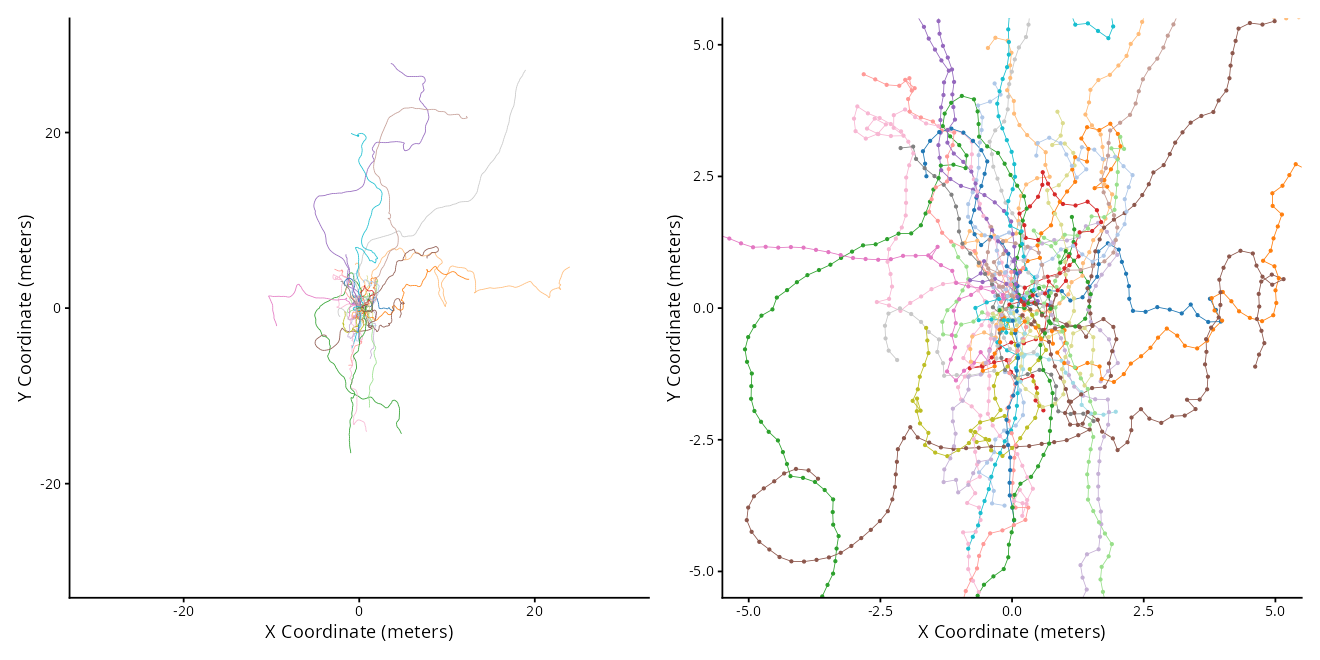

In [11]:
segments <- do.call(rbind, lapply(split(df, df$animal), function(g) {
  g <- g[order(g$iteration), ]
  n <- nrow(g)
  data.frame(animal_id = g$animal_id[-1L], iteration = g$iteration[-1L],
    x = g$X[-n], y = g$Y[-n], xend = g$X[-1L], yend = g$Y[-1L])
}))
tab20 <- c("#1F77B4", "#AEC7E8", "#FF7F0E", "#FFBB78", "#2CA02C", "#98DF8A",
           "#D62728", "#FF9896", "#9467BD", "#C5B0D5", "#8C564B", "#C49C94",
           "#E377C2", "#F7B6D2", "#7F7F7F", "#C7C7C7", "#BCBD22", "#DBDB8D",
           "#17BECF", "#9EDAE5")
trajectory_panel <- function(limit, points = FALSE) {
  p <- ggplot(segments, aes(x, y, colour = factor(animal_id %% 20L))) +
    geom_segment(aes(xend = xend, yend = yend), linewidth = 0.25) +
    scale_colour_manual(values = tab20) +
    coord_equal(xlim = c(-limit, limit), ylim = c(-limit, limit)) +
    labs(x = "X Coordinate (meters)", y = "Y Coordinate (meters)") +
    theme(legend.position = "none")
  if (points) p <- p + geom_point(data = df,
    aes(X, Y, colour = factor(animal_id %% 20L)), inherit.aes = FALSE, size = 0.6)
  p
}
p_trajectories <- trajectory_panel(30) + trajectory_panel(5, points = TRUE)
save_figure(p_trajectories, "locust_directional_trajectories", 12, 6)


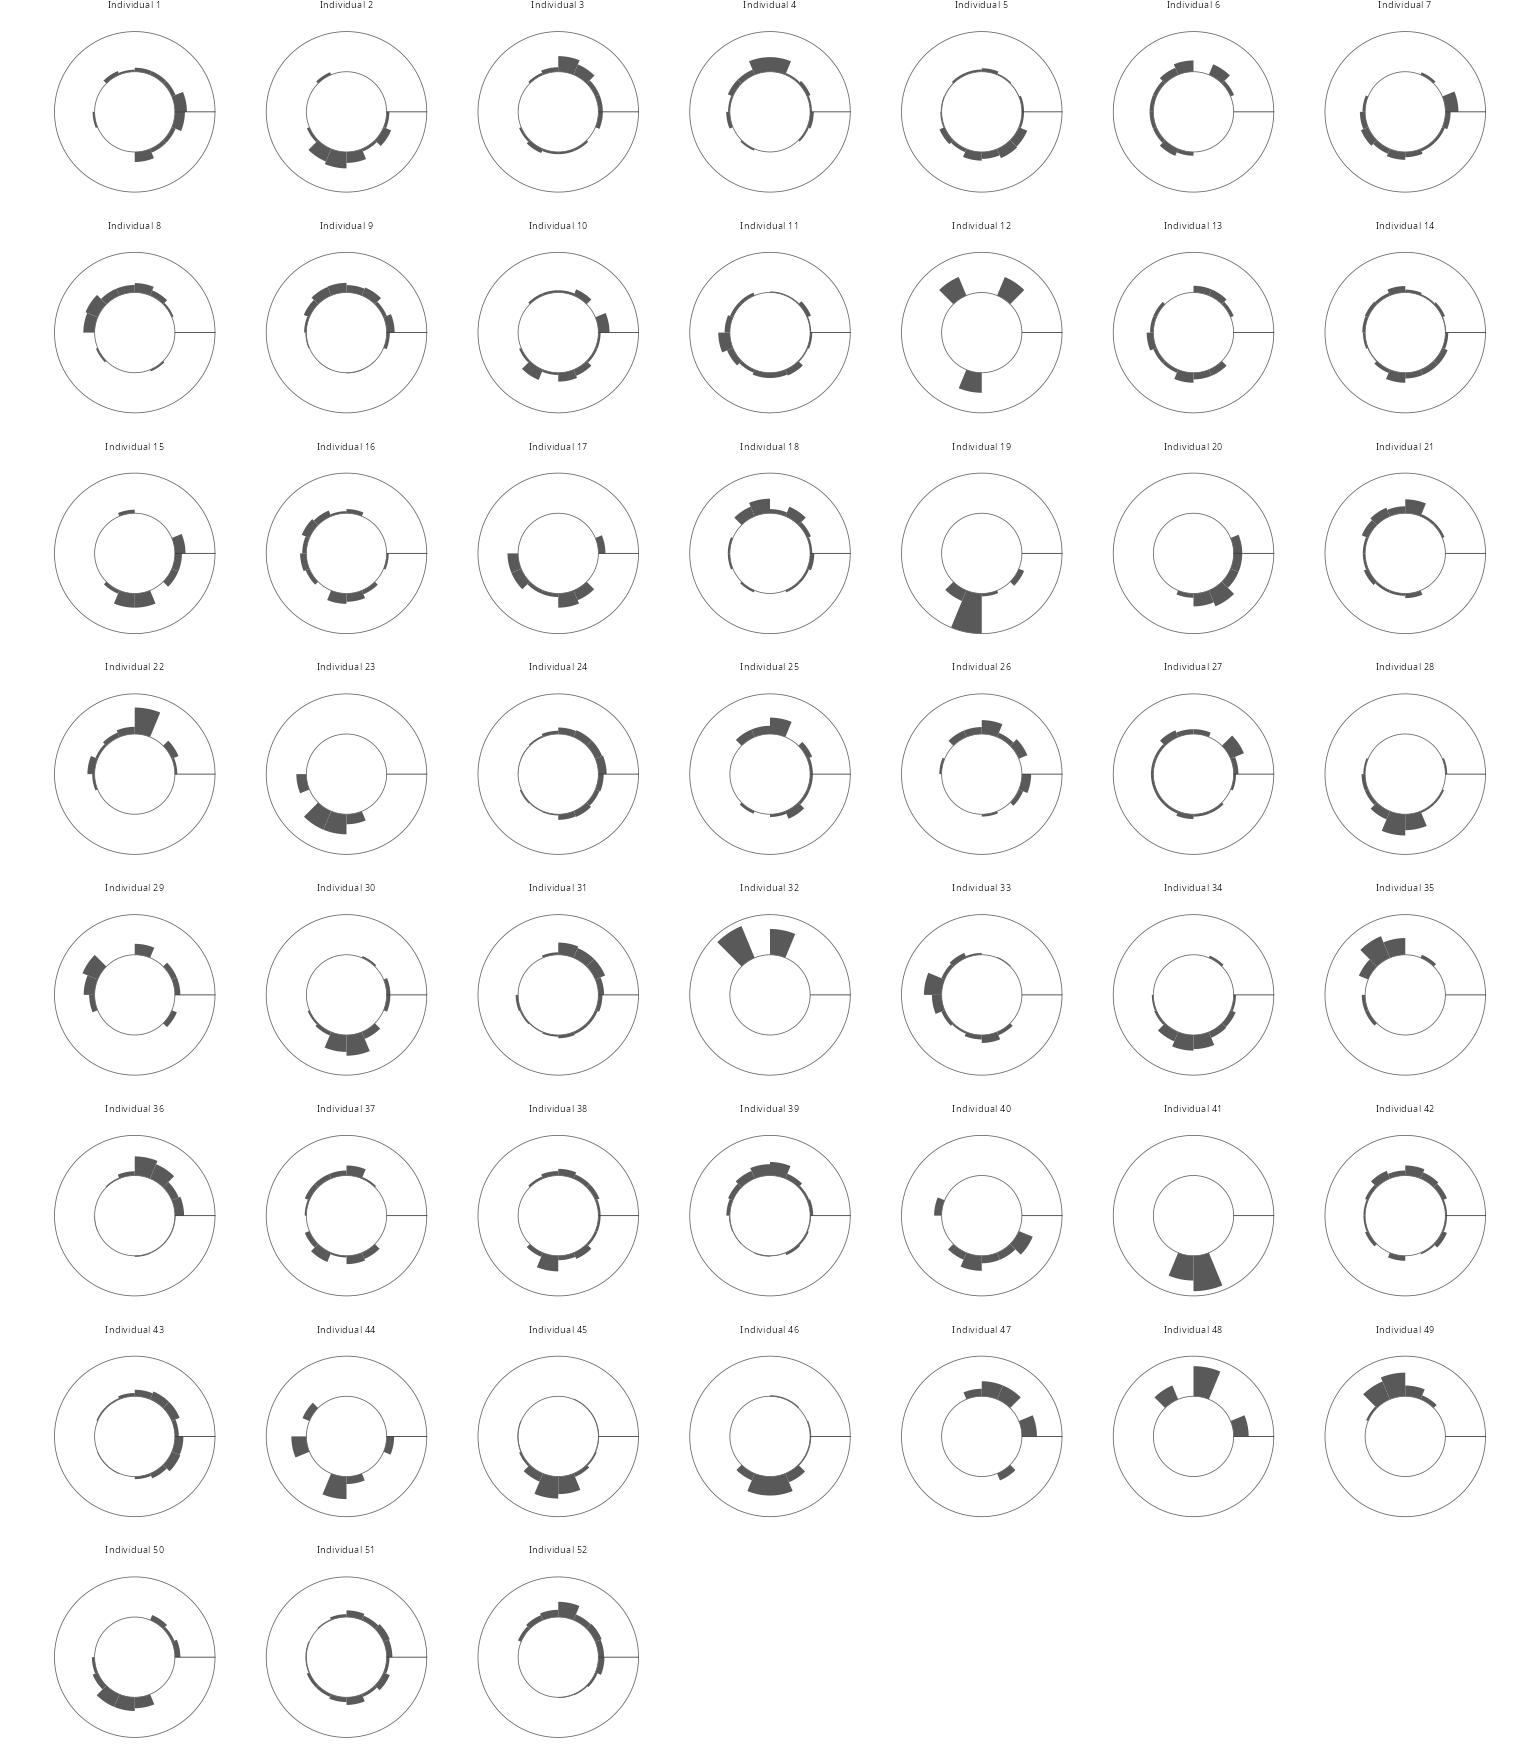

In [12]:
raw_bins <- seq(-pi, pi, length.out = 17L)
raw_densities <- do.call(rbind, lapply(seq_len(num_individuals), function(i) {
  y <- df$direction[df$animal_id == i - 1L]
  bin <- findInterval(wrap(y), raw_bins, rightmost.closed = TRUE)
  data.frame(individual = i, left = head(raw_bins, -1L), right = tail(raw_bins, -1L),
    density = tabulate(bin, nbins = 16L) / (length(y) * diff(raw_bins)))
}))
raw_densities$individual <- factor(raw_densities$individual,
  levels = seq_len(num_individuals), labels = paste("Individual", seq_len(num_individuals)))
# Same radius convention as the other polar figures: density zero sits on
# the ring at radius 1 (the bars rise from it) and the shared peak of all
# 52 histograms sits on the ring at radius 2; the 0-degree spoke marks the
# 3 o'clock zero of the mathematical orientation.
peak_max_hist <- max(raw_densities$density)
raw_densities$radius <- 1 + raw_densities$density / peak_max_hist
p_observed <- ggplot(raw_densities) +
  geom_rect(aes(xmin = left, xmax = right, ymin = 1, ymax = radius), fill = "grey35") +
  geom_hline(yintercept = c(1, 2), colour = "grey40", linewidth = 0.25) +
  geom_segment(data = data.frame(x = 0, xend = 0, y = 1, yend = 2.01),
    inherit.aes = FALSE,
    aes(x = x, xend = xend, y = y, yend = yend),
    colour = "grey20", linewidth = 0.25) +
  scale_x_continuous(limits = c(-pi, pi), expand = c(0, 0)) +
  scale_y_continuous(limits = c(0, 2.05), expand = c(0, 0)) +
  coord_polar(start = pi / 2, direction = -1) +
  facet_wrap(~ individual, ncol = 7) + theme_void(base_size = 8)
save_figure(p_observed, "locust_directional_observed_polar_grid", 14, 16)

## Modeling two directional tendencies within an animal

For locust $i$, the density of a heading $y$ is

$$
f_i(y)=\omega_i\,\mathcal M(y\mid\mu_{i,1},\kappa_{i,1})
+(1-\omega_i)\,\mathcal M(y\mid\mu_{i,2},\kappa_{i,2}),
$$

where $\mathcal M$ is a von Mises density. Each component has a mean direction $\mu_{i,k}$ and a concentration $\kappa_{i,k}$. The mean locates the preferred direction around the circle. Concentration describes how tightly headings cluster around it: higher concentration produces a narrower peak. The weight $\omega_i$ gives the modeled proportion of the animal's headings associated with the first component, with the remaining proportion assigned to the second.

These parameters separate three features of behavior: **where the animal tends to head, how consistently it heads there, and how strongly it favors one direction over the other**. An animal can favor one component strongly. Broad or overlapping components can also produce a distribution without two clearly separated peaks. The mixture therefore allows individual variation in the expression of the population's two directional tendencies.

### Sharing information across animals

The model relates each animal's parameters to shared population parameters through individual deviations:

$$
\mu_{i,k}=\operatorname{wrap}(\mu_{0,k}+b_{i,k}),
$$

$$
\operatorname{softplus}^{-1}(\kappa_{i,k})
=\operatorname{softplus}^{-1}(\kappa_{0,k})+a_{i,k},
\qquad
\operatorname{logit}(\omega_i)=\operatorname{logit}(\omega_0)+c_i.
$$

An angular deviation $b_{i,k}$ shifts the animal's preferred direction around the circle. A concentration deviation $a_{i,k}$ makes its headings more or less tightly clustered, and a weight deviation $c_i$ changes the balance between its components. Wrapping respects the equivalence of directions separated by a full turn. The softplus and inverse-logit transformations keep concentration positive and weights between zero and one.

The variation of preferred directions **between animals** is distinct from the concentration of headings **within an animal**. For example, several animals could each move consistently while preferring somewhat different directions. A hierarchical model can represent both features without mistaking disagreement among animals for inconsistency within each one. Setting the individual deviations to zero gives the shared population mixture used in the population figures.


### Priors and partial pooling

The population direction priors are almost uniform around the circle. They allow the observations to locate the component means, rather than fixing them at the forward or lateral directions. The hierarchical priors control how much individual directions, concentrations, and weights can depart from the shared parameters. This partial pooling stabilizes estimates for animals with few headings while allowing well-observed animals to show their own preferences.

The two components have interchangeable labels: swapping their complete parameter sets leaves the mixture density unchanged. The implementation keeps component parameters together when resolving their labels for summaries. The biological interpretation rests on the fitted directions, concentrations, weights, and complete density, rather than on a component being called “1” or “2.”


In [13]:
locust_mix <- custom_family("locust_mix",
  dpars = c("mu", "mutwo", "kappa", "kappatwo", "eta"),
  links = c("identity", "identity", "softplus", "softplus", "identity"),
  lb = c(NA, NA, 0, 0, NA), vars = "first_component", type = "real")
locust_vm <- custom_family("locust_vm", dpars = c("mu", "kappa"),
  links = c("identity", "softplus"), lb = c(NA, 0), type = "real")
vm_functions <- modulo_circular_fun + stan_unwrap_fun + stanvar(scode = "
  real locust_wrap(real x) {
    return atan2(sin(x), cos(x));
  }
  real locust_vm_lpdf(real y, real mu, real kappa) {
    return unwrap_von_mises_lpdf(y | locust_wrap(mu), kappa);
  }
  real unwrap_von_mises_vect_lpdf(vector y, real mu, real kappa) {
    real lp = 0;
    for (i in 1:num_elements(y)) lp += unwrap_von_mises_lpdf(y[i] | mu, kappa);
    return lp;
  }
", block = "functions")
mix_functions <- stanvar(scode = "
  real locust_mix_lpdf(real y, real mu, real mutwo, real kappa,
                       real kappatwo, real eta, real first_component) {
    array[2] real means = {mu, mutwo};
    array[2] real concentrations = {kappa, kappatwo};
    int first = first_component == 1 ? 1 : 2;
    int second = 3 - first;
    real sorted_eta = first == 1 ? eta : -eta;
    return log_sum_exp(
      log_inv_logit(sorted_eta) +
        unwrap_von_mises_lpdf(y | locust_wrap(means[first]), concentrations[first]),
      log_inv_logit(-sorted_eta) +
        unwrap_von_mises_lpdf(y | locust_wrap(means[second]), concentrations[second]));
  }
", block = "functions")
# A parameter-dependent order belongs in transformed parameters. Stan
# stores the first index as a real; the likelihood reconstructs the two
# integer indices locally. This is Python's argsort for two angles.
mix_order <- stanvar(scode = "
  real first_component = b_popone[1] <= b_poptwo[1] ? 1 : 2;
", block = "tparameters")
mix_hyper <- stanvar(scode = "real<lower=0> kmu_one; real<lower=0> kmu_two;",
                     block = "parameters")
# All animal coefficient vectors have the same level order, 0..51.
mix_form <- bf(direction ~ mu,
  nlf(mu ~ popone + devone),
  nlf(mutwo ~ poptwo + devtwo),
  popone ~ 1, poptwo ~ 1,
  devone ~ 0 + animal, devtwo ~ 0 + animal,
  kappa ~ 0 + Intercept + (1 | animal),
  kappatwo ~ 0 + Intercept + (1 | animal),
  eta ~ 0 + Intercept + (1 | animal),
  family = locust_mix)
mix_priors <- (
  prior("uniform(-pi(), pi())", class = "b", nlpar = "popone",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  prior("uniform(-pi(), pi())", class = "b", nlpar = "poptwo",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  prior("uniform(-pi(), pi())", class = "b", nlpar = "devone",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  prior("uniform(-pi(), pi())", class = "b", nlpar = "devtwo",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  set_prior("target += unwrap_von_mises_lpdf(b_popone[1] | 0, 1e-6)", check = FALSE) +
  set_prior("target += unwrap_von_mises_lpdf(b_poptwo[1] | 0, 1e-6)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_devone | 0, kmu_one)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_devtwo | 0, kmu_two)", check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_one | log(30), 0.1)", check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_two | log(30), 0.1)", check = FALSE) +
  prior("normal(log(exp(2) - 1), 0.5)", class = "b", coef = "Intercept", dpar = "kappa") +
  prior("normal(log(exp(2) - 1), 0.5)", class = "b", coef = "Intercept", dpar = "kappatwo") +
  prior("normal(0, 1.5)", class = "sd", dpar = "kappa") +
  prior("normal(0, 1.5)", class = "sd", dpar = "kappatwo") +
  prior("normal(0, 0.5)", class = "b", coef = "Intercept", dpar = "eta") +
  prior("normal(0, 3)", class = "sd", dpar = "eta")
)

check_angle_design <- function(stan, design, coefficients) {
  parameter_block <- regmatches(stan,
    regexpr("(?m)^parameters\\s*\\{[^}]*\\}", stan, perl = TRUE))
  parameter_block <- gsub("[[:space:]]", "", parameter_block)
  stopifnot(length(parameter_block) == 1L)
  for (name in names(coefficients)) {
    expected <- coefficients[[name]]
    declaration <- paste0("vector<lower=-3\\.14159[0-9]*,upper=3\\.14159[0-9]*>",
      "\\[K_", name, "\\]b_", name, ";")
    stopifnot(grepl(declaration, parameter_block),
      identical(colnames(design[[paste0("X_", name)]]), expected),
      design[[paste0("K_", name)]] == length(expected))
  }
}
mix_stanvars <- vm_functions + mix_functions + mix_hyper + mix_order
mix_stan <- make_stancode(mix_form, data = df, prior = mix_priors, stanvars = mix_stanvars)
mix_design <- make_standata(mix_form, data = df, prior = mix_priors, stanvars = mix_stanvars)
animal_design <- model.matrix(~ 0 + animal, data = df)
check_angle_design(mix_stan, mix_design,
  list(popone = "Intercept", poptwo = "Intercept",
    devone = colnames(animal_design), devtwo = colnames(animal_design)))
stopifnot(isTRUE(all.equal(mix_design$X_devone, animal_design, check.attributes = FALSE)),
          isTRUE(all.equal(mix_design$X_devtwo, animal_design, check.attributes = FALSE)))
compact_mix_stan <- gsub("[[:space:]]", "", mix_stan)
stopifnot(grepl("first_component=b_popone[1]<=b_poptwo[1]?1:2;", compact_mix_stan, fixed = TRUE),
          grepl("target\\+=locust_mix_lpdf\\([^;]+,first_component\\);", compact_mix_stan),
          grepl("unwrap_von_mises_vect_lpdf(b_devone|0,kmu_one)", compact_mix_stan, fixed = TRUE),
          grepl("unwrap_von_mises_vect_lpdf(b_devtwo|0,kmu_two)", compact_mix_stan, fixed = TRUE))
cat(mix_stan)

// generated with brms 2.23.0
functions {
  /* softplus link function inverse to 'log1p_exp'
   * Args:
   *   x: a positive scalar
   * Returns:
   *   a scalar in (-Inf, Inf)
   */
   real log_expm1(real x) {
     return log(expm1(x));
   }
  /* softplus link function inverse to 'log1p_exp' (vectorized)
   * Args:
   *   x: a positive vector
   * Returns:
   *   a vector in (-Inf, Inf)
   */
   vector log_expm1(vector x) {
     return log(expm1(x));
   }

  
  real modulo_circular(real y) {
    return fmod(y + pi(), 2*pi()) - pi();
  }

  
  real unwrap_von_mises_lpdf(real y, real mu, real kappa) {
    return von_mises_lpdf(y | modulo_circular(mu), kappa);
  }
  real unwrap_von_mises_rng(real mu, real kappa) {
    return von_mises_rng( modulo_circular(mu) , kappa);
  }

  
  real locust_wrap(real x) {
    return atan2(sin(x), cos(x));
  }
  real locust_vm_lpdf(real y, real mu, real kappa) {
    return unwrap_von_mises_lpdf(y | locust_wrap(mu), kappa);
  }
  real unwrap_von_mises_vect

### Fitting the two-component model

Posterior draws describe combinations of population and individual parameters that are supported by the headings and priors. Initial values help the sampler begin in plausible regions, while the fitted component directions remain free to move. The full fit uses four chains with 4,000 warmup iterations and 4,000 retained draws per chain. Comparing the chains is part of checking whether the resulting uncertainty summaries are reliable.


In [14]:
set.seed(SEED)
initial_clusters <- kmeans(cbind(cos(df$direction), sin(df$direction)),
                           centers = 2L, nstart = 20L)
cluster_means <- vapply(split(df$direction, initial_clusters$cluster), circ_mean, numeric(1))
cluster_order <- order(cluster_means)
anchor_mix <- as.numeric(mod_circular(cluster_means[cluster_order]))
initial_group <- match(initial_clusters$cluster, cluster_order)
animal_offsets <- function(component) {
  vapply(levels(df$animal), function(id) {
    y <- df$direction[df$animal == id & initial_group == component]
    if (!length(y)) 0 else mod_circular(circ_mean(y) - anchor_mix[component])
  }, numeric(1))
}
anchor_offsets_one <- animal_offsets(1L)
anchor_offsets_two <- animal_offsets(2L)
stopifnot(length(anchor_mix) == mix_design$K_popone + mix_design$K_poptwo,
          length(anchor_offsets_one) == mix_design$K_devone,
          length(anchor_offsets_two) == mix_design$K_devtwo,
          all(abs(anchor_mix) < pi - 0.2),
          all(abs(c(anchor_offsets_one, anchor_offsets_two)) < pi - 0.5))
mk_init <- function(anchor_seed) {
  set.seed(anchor_seed)
  j <- function(n) runif(n, -0.08, 0.08)
  list(b_popone = as.numeric(anchor_mix[1] + j(mix_design$K_popone)),
       b_poptwo = as.numeric(anchor_mix[2] + j(mix_design$K_poptwo)),
       b_devone = as.numeric(anchor_offsets_one + j(mix_design$K_devone)),
       b_devtwo = as.numeric(anchor_offsets_two + j(mix_design$K_devtwo)))
}
init_mix <- lapply(seq_len(CHAINS), function(k) mk_init(SEED + k))
set.seed(SEED)
fit_bimodal <- unwrap_load_fit_cache("locust_mix_bimodal", SEED, ITER, WARMUP)
if (is.null(fit_bimodal)) {
  fit_bimodal <- brm(mix_form, data = df, prior = mix_priors, stanvars = mix_stanvars,
    backend = "cmdstanr", chains = CHAINS, iter = ITER, warmup = WARMUP,
    cores = CHAINS, seed = SEED, init = init_mix,
    control = list(adapt_delta = 0.97, max_treedepth = 12))
  unwrap_save_fit_cache("locust_mix_bimodal", fit_bimodal, SEED, ITER, WARMUP)
}

Loading required namespace: rstan



Unwrap fit cache: reusing 'locust_mix_bimodal' (seed 42, iter 8000, warmup 4000).



In [15]:
animal_grid <- data.frame(animal = factor(levels(df$animal), levels = levels(df$animal)))
extract_state <- function(fit, bimodal = TRUE) {
  draws <- posterior::as_draws_array(fit)
  draw_index <- expand.grid(.iteration = seq_len(dim(draws)[1]),
    .chain = seq_len(dim(draws)[2]), KEEP.OUT.ATTRS = FALSE)
  get <- function(name) {
    stopifnot(name %in% posterior::variables(draws))
    as.numeric(draws[, , name])
  }
  predict_matrix <- function(dpar, transform = FALSE) {
    x <- t(posterior_linpred(fit, newdata = animal_grid,
                            dpar = dpar, transform = transform))
    stopifnot(identical(dim(x), c(num_individuals, nrow(draw_index))))
    x
  }
  m1 <- wrap(predict_matrix("mu"))
  k1 <- predict_matrix("kappa", transform = TRUE)
  p1 <- get("b_popone_Intercept")
  kp1 <- softplus(get("b_kappa_Intercept"))
  if (!bimodal) {
    return(list(draws = draw_index, muone = m1, kone = k1,
      pop_muone = matrix(wrap(p1), nrow = 1L),
      pop_kone = matrix(kp1, nrow = 1L),
      quantities = c(list(mu_pop = wrap(p1), mu_kappa = get("kmu_one"),
        kappa_log_pop = get("b_kappa_Intercept"), kappa_pop = kp1,
        kappa_sigma = get("sd_animal__kappa_Intercept")),
        setNames(lapply(seq_len(num_individuals), function(i) m1[i, ]),
                 paste0("mu[", seq_len(num_individuals), "]")),
        setNames(lapply(seq_len(num_individuals), function(i) k1[i, ]),
                 paste0("kappa[", seq_len(num_individuals), "]")))))
  }
  m2 <- wrap(predict_matrix("mutwo"))
  k2 <- predict_matrix("kappatwo", transform = TRUE)
  eta <- predict_matrix("eta")
  p2 <- get("b_poptwo_Intercept")
  kp2 <- softplus(get("b_kappatwo_Intercept"))
  eta_pop <- get("b_eta_Intercept")
  first_component <- get("first_component")
  stopifnot(all(first_component %in% 1:2),
            all((first_component == 2) == (p1 > p2)))
  swap <- first_component == 2
  # Read the saved Stan index for all summaries and predictive draws.
  reorder_pair <- function(a, b) {
    stopifnot(identical(dim(a), dim(b)), ncol(a) == length(swap))
    first <- a
    second <- b
    first[, swap] <- b[, swap, drop = FALSE]
    second[, swap] <- a[, swap, drop = FALSE]
    list(first, second)
  }
  means <- reorder_pair(m1, m2)
  kappas <- reorder_pair(k1, k2)
  pop_means <- reorder_pair(matrix(p1, nrow = 1L), matrix(p2, nrow = 1L))
  pop_kappas <- reorder_pair(matrix(kp1, nrow = 1L), matrix(kp2, nrow = 1L))
  pool_k <- reorder_pair(matrix(get("kmu_one"), nrow = 1L),
                         matrix(get("kmu_two"), nrow = 1L))
  sigma_k <- reorder_pair(matrix(get("sd_animal__kappa_Intercept"), nrow = 1L),
                          matrix(get("sd_animal__kappatwo_Intercept"), nrow = 1L))
  eta[, swap] <- -eta[, swap, drop = FALSE]
  eta_pop[swap] <- -eta_pop[swap]
  w <- plogis(eta)
  wp <- plogis(eta_pop)
  quantities <- list(logit_sigma = get("sd_animal__eta_Intercept"),
                     weights_pop = wp)
  for (k in 1:2) {
    quantities[[paste0("mu_pop[", k, "]")]] <- as.numeric(pop_means[[k]])
    quantities[[paste0("mu_kappa[", k, "]")]] <- as.numeric(pool_k[[k]])
    quantities[[paste0("kappa_pop[", k, "]")]] <- as.numeric(pop_kappas[[k]])
    quantities[[paste0("kappa_sigma[", k, "]")]] <- as.numeric(sigma_k[[k]])
    for (i in seq_len(num_individuals)) {
      quantities[[paste0("mu[", i, ",", k, "]")]] <- means[[k]][i, ]
      quantities[[paste0("kappa[", i, ",", k, "]")]] <- kappas[[k]][i, ]
    }
  }
  for (i in seq_len(num_individuals)) quantities[[paste0("weights[", i, "]")]] <- w[i, ]
  list(draws = draw_index, muone = means[[1]], mutwo = means[[2]],
       kone = kappas[[1]], ktwo = kappas[[2]], weight = w, eta = eta,
       pop_muone = pop_means[[1]], pop_mutwo = pop_means[[2]],
       pop_kone = pop_kappas[[1]], pop_ktwo = pop_kappas[[2]],
       pop_weight = matrix(wp, nrow = 1L), pop_eta = matrix(eta_pop, nrow = 1L),
       quantities = quantities)
}
chain_matrix <- function(x, draws) {
  stopifnot(length(x) == nrow(draws))
  ids <- split(seq_len(nrow(draws)), draws[[".chain"]])
  stopifnot(length(ids) >= 2L, length(unique(lengths(ids))) == 1L)
  do.call(cbind, lapply(ids, function(ii) x[ii[order(draws[[".iteration"]][ii])]]))
}
diagnose_fit <- function(fit, state) {
  # Same retained-flag probe as the P1 helpers; absence is not zero.
  divergences <- tryCatch({
    samples <- fit$fit@sim$samples
    if (is.null(samples) || !length(samples)) {
      NA_real_
    } else {
      flags <- lapply(samples, function(ch) ch[["divergent"]])
      if (any(vapply(flags, is.null, logical(1)))) NA_real_ else sum(unlist(flags))
    }
  }, error = function(e) NA_real_)
  if (is.na(divergences)) {
    cat("Divergences: not retained in this fit object.\n")
  } else {
    cat("Divergences:", divergences, "\n")
  }
  table <- do.call(rbind, lapply(names(state$quantities), function(p) {
    x <- chain_matrix(state$quantities[[p]], state$draws)
    stopifnot(all(is.finite(x)))
    angular <- grepl("^mu(\\[|_pop($|\\[))", p)
    z <- if (angular) wrap(x - circ_mean(x)) else x
    data.frame(parameter = p,
      mean = if (angular) circ_mean(x) else mean(x),
      sd = if (angular) sqrt(-2 * log(min(1, resultant(x)))) else sd(as.numeric(x)),
      rhat = if (angular) Rhat_unwrap(x, method = "sine") else posterior::rhat(x),
      ess_bulk = posterior::ess_bulk(z), row.names = NULL)
  }))
  # Angular R-hat uses the Rhat_unwrap sine/cosine convention. Every ESS
  # and R-hat calculation receives an [iteration x chain] matrix.
  failed <- table[!is.finite(table$rhat) | table$rhat >= 1.01 |
    !is.finite(table$ess_bulk) | table$ess_bulk <= 400, , drop = FALSE]
  print(failed, row.names = FALSE)
  stopifnot(nrow(failed) == 0L, is.na(divergences) || divergences == 0)
  table
}
trace_plot <- function(state, parameters) {
  long <- do.call(rbind, lapply(parameters, function(p) {
    x <- state$quantities[[p]]
    stopifnot(!is.null(x))
    if (grepl("^mu(\\[|_pop($|\\[))", p)) x <- wrap(x - circ_mean(x))
    data.frame(parameter = p, iteration = state$draws[[".iteration"]],
               chain = factor(state$draws[[".chain"]]), value = x)
  }))
  ggplot(long, aes(iteration, value, colour = chain, group = chain)) +
    geom_line(linewidth = 0.25, alpha = 0.65) +
    facet_wrap(~ parameter, scales = "free_y", ncol = 2) +
    labs(x = "retained iteration", y = "draw (angular traces centered)") +
    theme(legend.position = "bottom")
}
state_bimodal <- extract_state(fit_bimodal)
summary_bimodal <- diagnose_fit(fit_bimodal, state_bimodal)

Divergences: not retained in this fit object.
[1] parameter mean      sd        rhat      ess_bulk 
<0 rows> (or 0-length row.names)


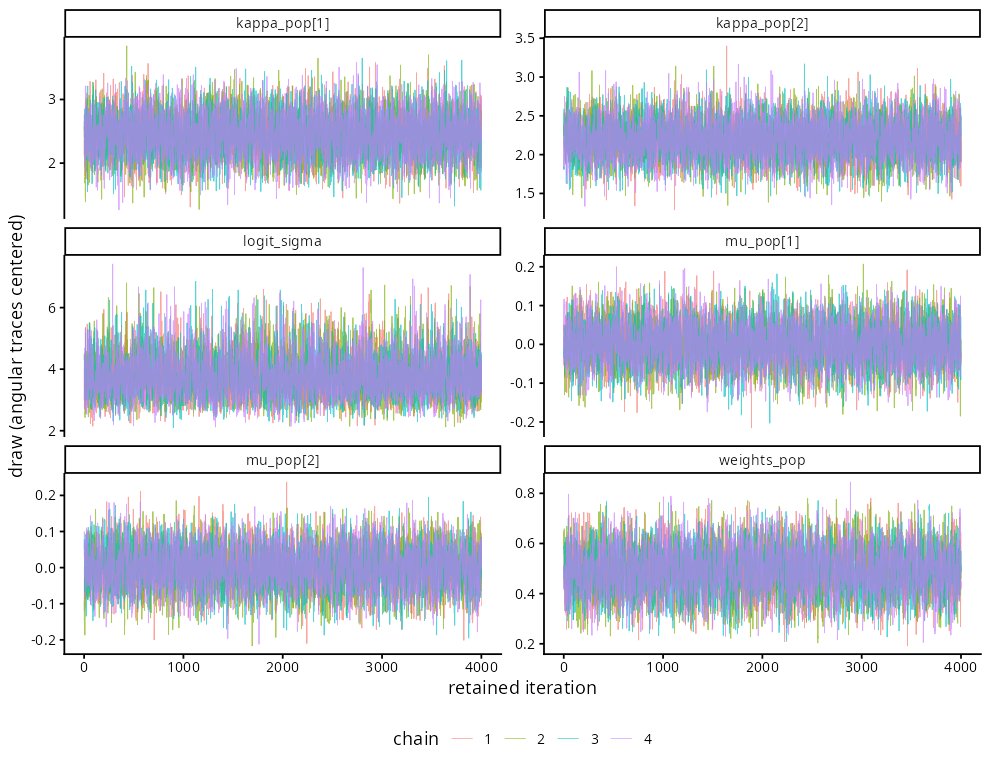

In [16]:
save_figure(trace_plot(state_bimodal,
  c("mu_pop[1]", "mu_pop[2]", "kappa_pop[1]", "kappa_pop[2]", "weights_pop", "logit_sigma")),
  "bimodal_trace", 9, 7)


## Comparing one and two directional tendencies

We also fit a hierarchical model with one von Mises distribution per animal,

$$
f_i(y)=\mathcal M(y\mid\mu_i,\kappa_i).
$$

This alternative already allows animals to prefer different directions. Consequently, it can produce two peaks in a population summary if some animals mainly turn left and others mainly turn right. Comparing it with the mixture asks the more specific question of whether allowing two components **within an animal** improves prediction of its headings.

Both models estimate their mean directions from the data. The one-component model is therefore not constrained to forward movement, and the mixture is not constrained to lateral movement. They compare descriptions of heading distributions. The mechanistic hypotheses are assessed later through the directions they predict. The models' concentration and pooling priors also differ, so the predictive comparison concerns the fitted specifications as a whole.


In [17]:
uni_hyper <- stanvar(scode = "real<lower=0> kmu_one;", block = "parameters")
uni_form <- bf(direction ~ mu,
  nlf(mu ~ popone + devone),
  popone ~ 1, devone ~ 0 + animal,
  kappa ~ 0 + Intercept + (1 | animal), family = locust_vm)
uni_priors <- (
  prior("uniform(-pi(), pi())", class = "b", nlpar = "popone",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  prior("uniform(-pi(), pi())", class = "b", nlpar = "devone",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  set_prior("target += unwrap_von_mises_lpdf(b_popone[1] | 0, 1e-6)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_devone | 0, kmu_one)", check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_one | log(10), 0.1)", check = FALSE) +
  prior("normal(log(exp(1.5) - 1), 0.5)", class = "b", coef = "Intercept", dpar = "kappa") +
  prior("normal(0, 1.5)", class = "sd", dpar = "kappa")
)
uni_stanvars <- vm_functions + uni_hyper
uni_stan <- make_stancode(uni_form, data = df, prior = uni_priors, stanvars = uni_stanvars)

uni_design <- make_standata(uni_form, data = df, prior = uni_priors, stanvars = uni_stanvars)
check_angle_design(uni_stan, uni_design,
  list(popone = "Intercept", devone = colnames(animal_design)))
stopifnot(isTRUE(all.equal(uni_design$X_devone, animal_design, check.attributes = FALSE)))
compact_uni_stan <- gsub("[[:space:]]", "", uni_stan)
stopifnot(grepl("target+=locust_vm_lpdf", compact_uni_stan, fixed = TRUE),
          grepl("unwrap_von_mises_vect_lpdf(b_devone|0,kmu_one)", compact_uni_stan, fixed = TRUE),
          grepl("lognormal_lpdf(kmu_one|log(10),0.1)", compact_uni_stan, fixed = TRUE))
cat(uni_stan)

// generated with brms 2.23.0
functions {
  /* softplus link function inverse to 'log1p_exp'
   * Args:
   *   x: a positive scalar
   * Returns:
   *   a scalar in (-Inf, Inf)
   */
   real log_expm1(real x) {
     return log(expm1(x));
   }
  /* softplus link function inverse to 'log1p_exp' (vectorized)
   * Args:
   *   x: a positive vector
   * Returns:
   *   a vector in (-Inf, Inf)
   */
   vector log_expm1(vector x) {
     return log(expm1(x));
   }
  
  real modulo_circular(real y) {
    return fmod(y + pi(), 2*pi()) - pi();
  }

  
  real unwrap_von_mises_lpdf(real y, real mu, real kappa) {
    return von_mises_lpdf(y | modulo_circular(mu), kappa);
  }
  real unwrap_von_mises_rng(real mu, real kappa) {
    return von_mises_rng( modulo_circular(mu) , kappa);
  }

  
  real locust_wrap(real x) {
    return atan2(sin(x), cos(x));
  }
  real locust_vm_lpdf(real y, real mu, real kappa) {
    return unwrap_von_mises_lpdf(y | locust_wrap(mu), kappa);
  }
  real unwrap_von_mises_vect_

### Sampling diagnostics

The displayed convergence and effective-sample-size checks flag no parameters in the R fits. The fit objects report divergence information as unavailable, so these summaries do not establish that the sampler encountered zero divergences. These checks concern exploration of the posterior; the leave-one-out diagnostics below assess a separate approximation used for predictive comparison.


In [18]:
data_anchor <- as.numeric(mod_circular(circ_mean(df$direction)))
individual_anchor <- vapply(split(df$direction, df$animal), circ_mean, numeric(1))
anchor_offsets <- as.numeric(mod_circular(individual_anchor - data_anchor))
if (abs(data_anchor) >= pi - 0.2 || any(abs(anchor_offsets) >= pi - 0.5)) {
  ordered_means <- sort(individual_anchor)
  gaps <- diff(c(ordered_means, ordered_means[1] + 2 * pi))
  widest <- which.max(gaps)
  seam <- ordered_means[widest] + gaps[widest] / 2
  data_anchor <- as.numeric(mod_circular(seam + pi))
  anchor_offsets <- as.numeric(mod_circular(individual_anchor - data_anchor))
}
stopifnot(length(data_anchor) == uni_design$K_popone,
          length(anchor_offsets) == uni_design$K_devone,
          abs(data_anchor) < pi - 0.2, all(abs(anchor_offsets) < pi - 0.5))
mk_init <- function(anchor_seed) {
  set.seed(anchor_seed)
  j <- function(n) runif(n, -0.08, 0.08)
  list(b_popone = as.numeric(data_anchor + j(uni_design$K_popone)),
       b_devone = as.numeric(anchor_offsets + j(uni_design$K_devone)))
}
init_uni <- lapply(seq_len(CHAINS), function(k) mk_init(SEED + k))
set.seed(SEED)
fit_unimodal <- unwrap_load_fit_cache("locust_mix_unimodal", SEED, ITER, WARMUP)
if (is.null(fit_unimodal)) {
  fit_unimodal <- brm(uni_form, data = df, prior = uni_priors, stanvars = uni_stanvars,
    backend = "cmdstanr", chains = CHAINS, iter = ITER, warmup = WARMUP,
    cores = CHAINS, seed = SEED, init = init_uni,
    control = list(adapt_delta = 0.97, max_treedepth = 12))
  unwrap_save_fit_cache("locust_mix_unimodal", fit_unimodal, SEED, ITER, WARMUP)
}
state_unimodal <- extract_state(fit_unimodal, bimodal = FALSE)
summary_unimodal <- diagnose_fit(fit_unimodal, state_unimodal)

Unwrap fit cache: reusing 'locust_mix_unimodal' (seed 42, iter 8000, warmup 4000).



Divergences: not retained in this fit object.
[1] parameter mean      sd        rhat      ess_bulk 
<0 rows> (or 0-length row.names)


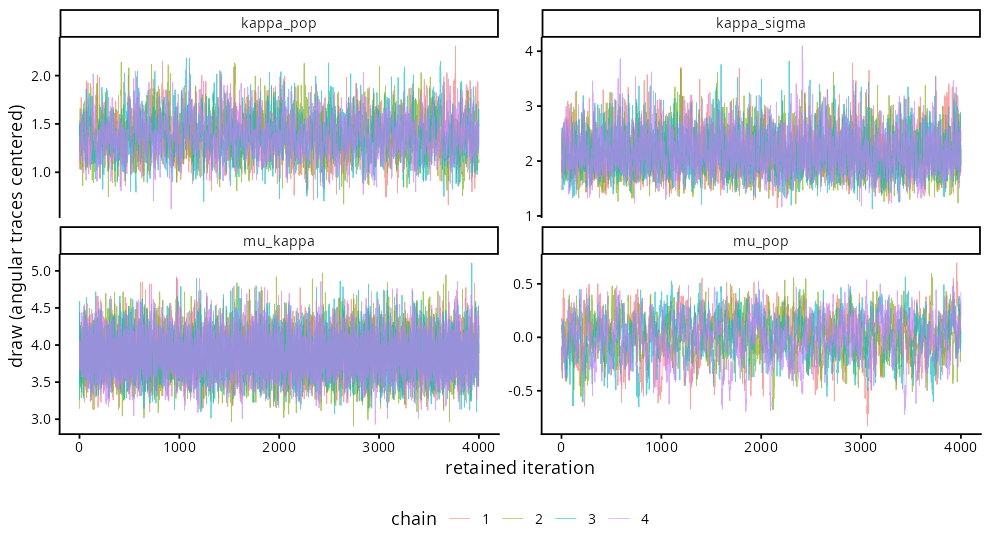

In [19]:
save_figure(trace_plot(state_unimodal,
  c("mu_pop", "mu_kappa", "kappa_pop", "kappa_sigma")), "unimodal_trace", 9, 5)


## Predictive comparison

We compare the models using Pareto-smoothed importance-sampling leave-one-out cross-validation, abbreviated PSIS-LOO. For each heading, it approximates how much predictive density the model would assign to that observation if it were omitted from the fit. The other headings from the same animal remain available. This evaluates prediction of another heading from an observed animal; prediction for an entirely new animal would require withholding that animal's observations together.

Expected log predictive density, or ELPD, sums these held-out predictive contributions. Higher values indicate better prediction. The comparison favors the two-component mixture, consistent with directional structure that a single preferred direction per animal describes less well.

The individual panels show which animals benefit most from allowing a second directional component. Read these differences alongside the individual heading distributions and observation counts. Each animal's score is the sum of its heading contributions, so animals with more observations can contribute more to the total. The current individual panels do not estimate uncertainty intervals for those sums.

Some headings have high Pareto-$k$ values, indicating that the importance-sampling approximation is less reliable for them. The reported numerical advantage should be read with that qualification. The distributional checks that follow provide a complementary way to see which observed features the two-component model captures more successfully.



Computed from 16000 posterior draws and 2435 log-likelihood terms.

         Estimate   SE
elpd_loo  -3404.5 39.2
p_loo       119.5  3.7
looic      6809.0 78.5
------
MCSE of elpd_loo is NA.
MCSE and ESS estimates assume MCMC draws (r_eff in [0.2, 2.4]).

Pareto k diagnostic values:
                         Count Pct.    Min. ESS
(-Inf, 0.7]   (good)     2434  100.0%  3039    
   (0.7, 1]   (bad)         1    0.0%  <NA>    
   (1, Inf)   (very bad)    0    0.0%  <NA>    
See help('pareto-k-diagnostic') for details.
Pareto k diagnostic values:
                         Count Pct.    Min. ESS
(-Inf, 0.7]   (good)     2434  100.0%  3039    
   (0.7, 1]   (bad)         1    0.0%  <NA>    
   (1, Inf)   (very bad)    0    0.0%  <NA>    



Computed from 16000 posterior draws and 2435 log-likelihood terms.

         Estimate   SE
elpd_loo  -3501.2 38.8
p_loo        92.3  3.6
looic      7002.5 77.5
------
MCSE of elpd_loo is NA.
MCSE and ESS estimates assume MCMC draws (r_eff in [0.1, 2.0]).

Pareto k diagnostic values:
                         Count Pct.    Min. ESS
(-Inf, 0.7]   (good)     2428  99.7%   1032    
   (0.7, 1]   (bad)         5   0.2%   <NA>    
   (1, Inf)   (very bad)    2   0.1%   <NA>    
See help('pareto-k-diagnostic') for details.
Pareto k diagnostic values:
                         Count Pct.    Min. ESS
(-Inf, 0.7]   (good)     2428  99.7%   1032    
   (0.7, 1]   (bad)         5   0.2%   <NA>    
   (1, Inf)   (very bad)    2   0.1%   <NA>    


     model      elpd       se max_pareto_k n_pareto_k_gt_0.7
1  Bimodal -3404.488 39.24214    0.7041202                 1
2 Unimodal -3501.249 38.76290    1.4213408                 7


          comparison delta_elpd       se
1 Bimodal - Unimodal   96.76108 16.71045


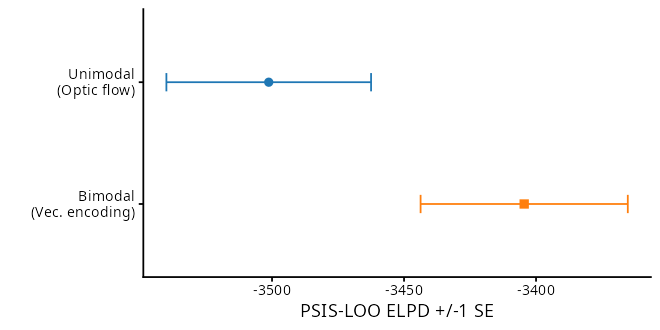

In [20]:
explicit_loo <- function(state, bimodal = TRUE, chunk_size = 128L) {
  S <- nrow(state$draws)
  ll <- matrix(NA_real_, nrow = S, ncol = nrow(df))
  for (start in seq.int(1L, nrow(df), by = chunk_size)) {
    ii <- seq.int(start, min(start + chunk_size - 1L, nrow(df)))
    a <- df$animal_id[ii] + 1L
    y <- matrix(rep(df$direction[ii], S), nrow = length(ii))
    l1 <- vm_logpdf(y, state$muone[a, , drop = FALSE], state$kone[a, , drop = FALSE])
    if (bimodal) {
      eta <- state$eta[a, , drop = FALSE]
      l2 <- vm_logpdf(y, state$mutwo[a, , drop = FALSE], state$ktwo[a, , drop = FALSE])
      ll[, ii] <- t(log_add(-softplus(-eta) + l1, -softplus(eta) + l2))
    } else {
      ll[, ii] <- t(l1)
    }
  }
  stopifnot(all(is.finite(ll)))
  # Scale each likelihood column before exponentiating; relative_eff is
  # invariant to this scaling. Preserve chain IDs rather than flattening.
  likelihood <- exp(sweep(ll, 2, apply(ll, 2, max), "-"))
  r_eff <- loo::relative_eff(likelihood, chain_id = state$draws[[".chain"]])
  # The full Pareto-k table is printed below and its summary columns are
  # carried in the ELPD table, so suppress loo()'s redundant high-k nag.
  result <- suppressWarnings(loo::loo(ll, r_eff = r_eff))
  print(result)
  print(loo::pareto_k_table(result))
  result
}
loo_bimodal <- explicit_loo(state_bimodal)
loo_unimodal <- explicit_loo(state_unimodal, bimodal = FALSE)
models <- list(Bimodal = loo_bimodal, Unimodal = loo_unimodal)
elpd_table <- do.call(rbind, lapply(names(models), function(name) {
  x <- models[[name]]
  data.frame(model = name, elpd = x$estimates["elpd_loo", "Estimate"],
    se = x$estimates["elpd_loo", "SE"], max_pareto_k = max(x$diagnostics$pareto_k),
    n_pareto_k_gt_0.7 = sum(x$diagnostics$pareto_k > 0.7))
}))
delta_pointwise <- loo_bimodal$pointwise[, "elpd_loo"] - loo_unimodal$pointwise[, "elpd_loo"]
print(elpd_table)
print(data.frame(comparison = "Bimodal - Unimodal", delta_elpd = sum(delta_pointwise),
                 se = sqrt(length(delta_pointwise) * var(delta_pointwise))))
model_labels <- c(Bimodal = "Bimodal\n(Vec. encoding)",
                  Unimodal = "Unimodal\n(Optic flow)")
p_elpd <- ggplot(elpd_table, aes(elpd, factor(model, levels = c("Bimodal", "Unimodal")),
                                 colour = model, shape = model)) +
  scale_y_discrete(labels = model_labels) +
  geom_errorbar(aes(xmin = elpd - se, xmax = elpd + se), orientation = "y", width = 0.15) +
  geom_point(size = 2.5) + scale_colour_manual(values = c(Bimodal = ORANGE, Unimodal = BLUE)) +
  scale_shape_manual(values = c(Bimodal = 15, Unimodal = 16)) +
  labs(x = "PSIS-LOO ELPD +/-1 SE", y = "") + theme(legend.position = "none")
save_figure(p_elpd, "locust_bimodal_unimodal_elpd", 6, 3)

   individual     bimodal    unimodal        delta se
1           1  -52.290633  -48.239118 -4.051515272  0
2           2  -29.200144  -29.636264  0.436119763  0
3           3  -42.504613  -46.484657  3.980043784  0
4           4  -48.268254  -48.515547  0.247293092  0
5           5 -221.750157 -227.425627  5.675470136  0
6           6  -28.978190  -30.228898  1.250707561  0
7           7  -40.658411  -41.288575  0.630164380  0
8           8  -44.382584  -43.615377 -0.767206674  0
9           9 -265.642243 -265.376966 -0.265276848  0
10         10  -47.947087  -48.261641  0.314553703  0
11         11 -101.885222 -101.154228 -0.730994131  0
12         12   -5.912389   -6.393047  0.480658412  0
13         13  -33.714467  -33.784872  0.070405560  0
14         14 -147.389958 -154.148429  6.758471145  0
15         15  -25.712210  -25.346273 -0.365937019  0
16         16  -53.175990  -54.021250  0.845259105  0
17         17  -25.864033  -26.668937  0.804903611  0
18         18  -45.749676  -

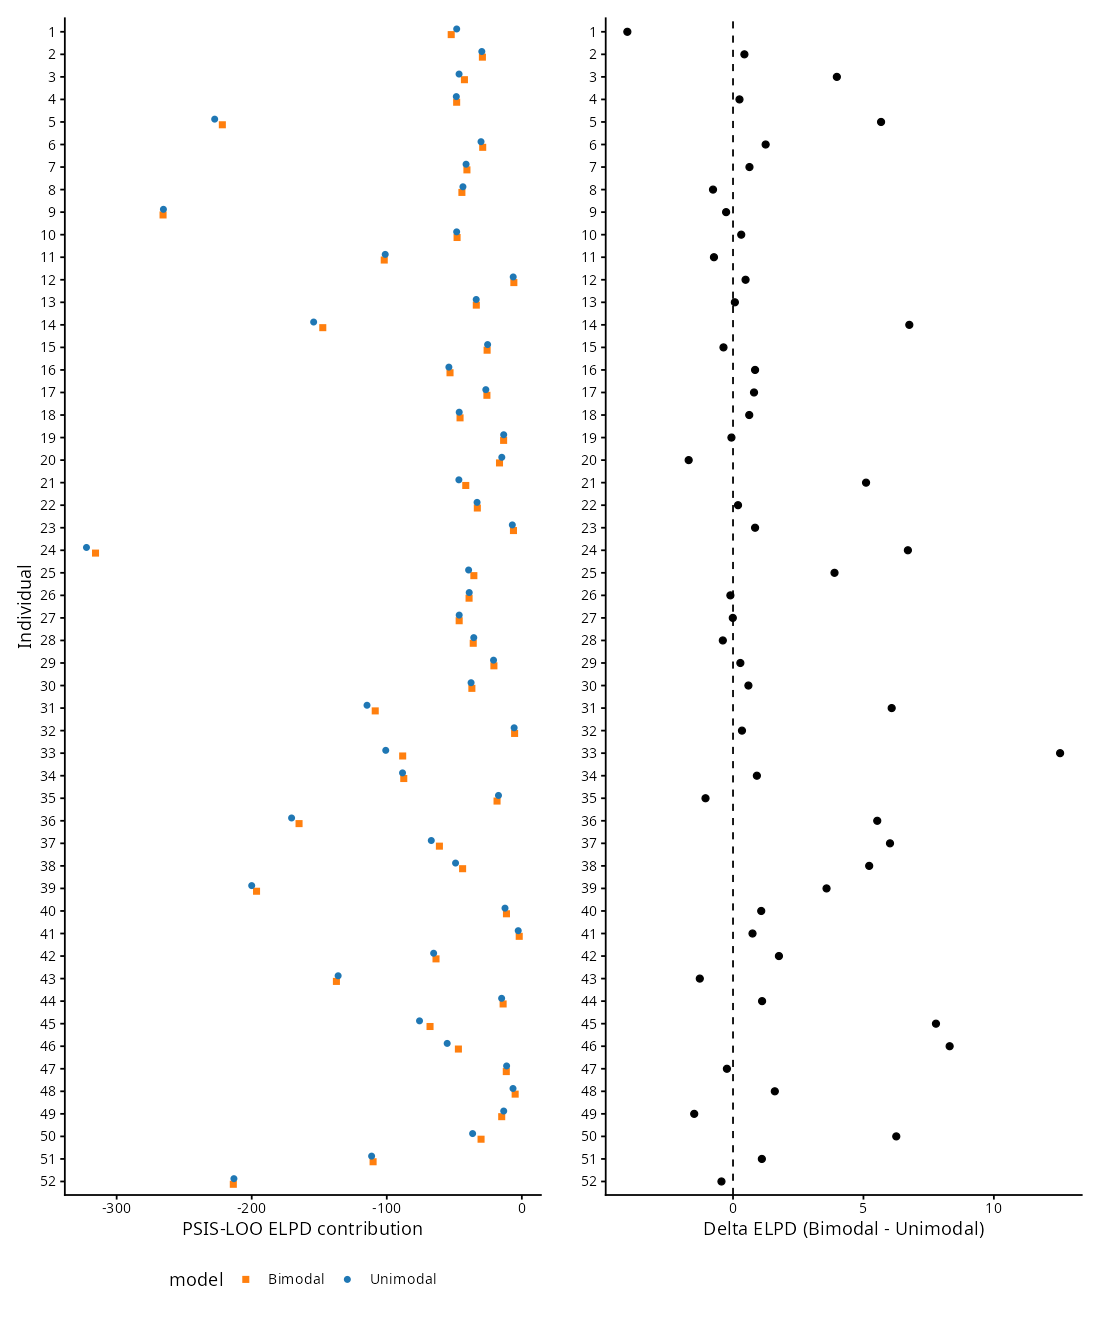

In [21]:
elpd_individual <- do.call(rbind, lapply(seq_len(num_individuals), function(i) {
  ii <- which(df$animal_id == i - 1L)
  data.frame(individual = i,
    bimodal = sum(loo_bimodal$pointwise[ii, "elpd_loo"]),
    unimodal = sum(loo_unimodal$pointwise[ii, "elpd_loo"]),
    delta = sum(delta_pointwise[ii]), se = 0)
}))
print(elpd_individual)
individual_levels <- rev(as.character(seq_len(num_individuals)))
elpd_long <- rbind(data.frame(individual = elpd_individual$individual,
                             value = elpd_individual$bimodal, model = "Bimodal"),
                   data.frame(individual = elpd_individual$individual,
                             value = elpd_individual$unimodal, model = "Unimodal"))
p_elpd_individual <- ggplot(elpd_long,
  aes(value, factor(individual, levels = individual_levels), colour = model, shape = model)) +
  geom_point(position = position_dodge(width = 0.5), size = 1.8) +
  scale_colour_manual(values = c(Bimodal = ORANGE, Unimodal = BLUE)) +
  scale_shape_manual(values = c(Bimodal = 15, Unimodal = 16)) +
  labs(x = "PSIS-LOO ELPD contribution", y = "Individual") + theme(legend.position = "bottom")
p_delta <- ggplot(elpd_individual,
  aes(delta, factor(individual, levels = individual_levels))) +
  geom_point(size = 1.8) + geom_vline(xintercept = 0, linetype = "dashed") +
  labs(x = "Delta ELPD (Bimodal - Unimodal)", y = "")
save_figure(p_elpd_individual + p_delta,
  "locust_elpd_by_individual_ab", 10, 12)


## The population heading distribution

The population figures show two broad peaks near the directions of the left and right virtual groups, with less density near the forward direction. This is the behavioral feature that distinguishes the experimental predictions: headings are concentrated toward the flanks rather than around continued forward marching.

The fitted mixture follows both peaks and the trough between them. Compare the positions, widths, and relative heights of the peaks with the histogram and smoothed estimate of the observations. Agreement in peak locations indicates that the model captures the main preferred directions; differences in width and height reveal how well it describes their consistency and relative prevalence. The Cartesian and polar plots display the same distribution in different coordinates.


The red model curve uses the shared population parameters, with individual deviations set to zero. It represents the common directional pattern estimated by the hierarchy. Its band shows posterior uncertainty in that fitted density.

The observed-data summaries give each animal equal weight. Their hierarchical bootstrap resamples animals and then headings within each selected animal, so an animal with a long recording does not dominate the population curve simply by contributing more observations. The histogram groups headings into angular bins; the circular kernel density estimate provides a smooth view of the same pattern. Bootstrap bands show how these summaries vary under resampling.

The fitted population curve and the empirical average over animals describe related quantities, but they need not coincide exactly when individuals vary. The model band concerns uncertainty in the shared parameters, while the bootstrap band concerns variation in the observed summary. The later replicated-heading checks compare the observations with simulated datasets containing the same animals and numbers of headings.


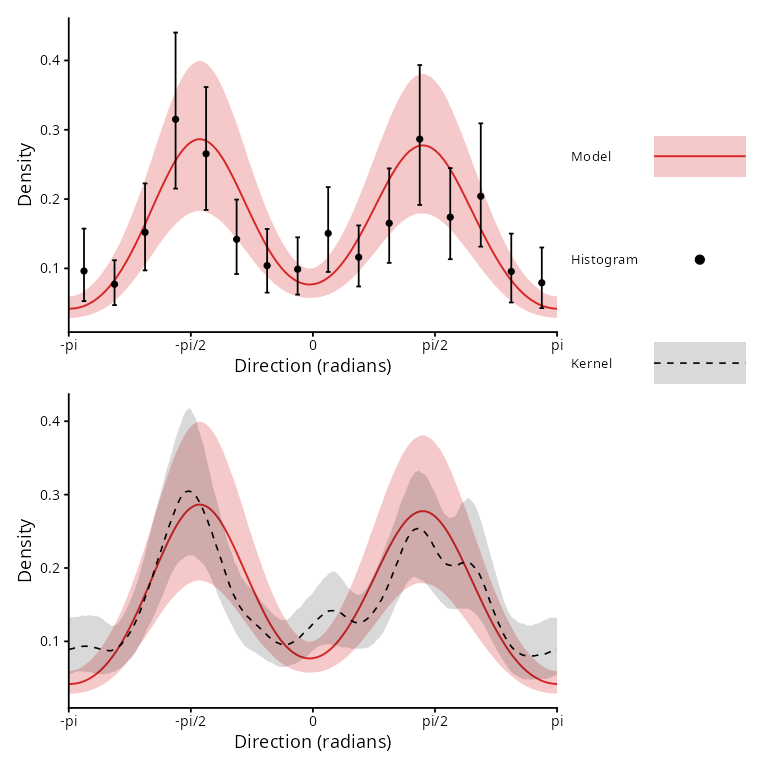

In [22]:
population_state <- list(muone = state_bimodal$pop_muone,
  mutwo = state_bimodal$pop_mutwo, kone = state_bimodal$pop_kone,
  ktwo = state_bimodal$pop_ktwo, weight = state_bimodal$pop_weight,
  eta = state_bimodal$pop_eta)
theta_grid <- seq(-pi, pi, length.out = 360L)
pop_mu <- rbind(as.numeric(population_state$muone), as.numeric(population_state$mutwo))
pop_kappa <- rbind(as.numeric(population_state$kone), as.numeric(population_state$ktwo))
pop_pdf <- mixture_grid(theta_grid, pop_mu, pop_kappa, as.numeric(population_state$weight))
stopifnot(identical(dim(pop_pdf), c(length(theta_grid), nrow(state_bimodal$draws))))
# Python population_density summarizes log density first, then exponentiates.
q_pop <- exp(t(apply(log(pop_pdf), 1, quantile, probs = c(0.025, 0.5, 0.975))))
model_density <- data.frame(theta = theta_grid,
  low = q_pop[, 1], center = q_pop[, 2], high = q_pop[, 3])
rm(pop_pdf)
rows_by_animal <- split(seq_len(nrow(df)), df$animal)
bins <- seq(-pi, pi, length.out = 17L)
bin_width <- diff(bins)[1]
bin_id <- findInterval(wrap(df$direction), bins, rightmost.closed = TRUE)
stopifnot(all(bin_id >= 1L & bin_id <= 16L))
hist_kernel <- matrix(0, nrow = 16L, ncol = nrow(df))
hist_kernel[cbind(bin_id, seq_len(nrow(df)))] <- 1 / bin_width
# Each column is one observed heading's VM kernel on the theta grid.
kde_kernel <- kde_basis(theta_grid, df$direction, bw = 30)
boot_hist <- matrix(0, nrow = 16L, ncol = N_BOOTSTRAPS)
boot_kde <- matrix(0, nrow = length(theta_grid), ncol = N_BOOTSTRAPS)
set.seed(123)
for (b in seq_len(N_BOOTSTRAPS)) {
  selected <- sample.int(num_individuals, num_individuals, replace = TRUE)
  weights <- numeric(nrow(df))
  for (i in selected) {
    ii <- rows_by_animal[[i]]
    draw <- sample.int(length(ii), length(ii), replace = TRUE)
    weights[ii] <- weights[ii] + tabulate(draw, nbins = length(ii)) /
      (num_individuals * length(ii))
  }
  stopifnot(abs(sum(weights) - 1) < 1e-10)
  boot_hist[, b] <- as.numeric(hist_kernel %*% weights)
  boot_kde[, b] <- as.numeric(kde_kernel %*% weights)
}
bin_centers <- head(bins, -1L) + bin_width / 2
hist_density <- density_frame(bin_centers, boot_hist)
kde_density <- density_frame(theta_grid, boot_kde)
rm(hist_kernel, kde_kernel, boot_hist, boot_kde)
invisible(gc())
model_layer <- function() {
  ggplot(model_density, aes(theta, center)) +
    geom_ribbon(aes(ymin = low, ymax = high), fill = RED, alpha = 0.25) +
    geom_line(colour = RED, linewidth = 0.6) +
    scale_x_continuous(breaks = angle_breaks, labels = angle_labels,
                       limits = c(-pi, pi), expand = c(0, 0)) +
    labs(x = "Direction (radians)", y = "Density")
}
# Hand-drawn Model/Histogram/Kernel legend, matching the Python patch+line
# legend handlers. Built with annotate() (no ggplot2 legend-key geoms) so it
# emits no warning streams; placed as a right-hand patchwork column.
val_legend <- function(framed = FALSE) {
  lp <- ggplot(data.frame(y = c(8, 6.5, 5)), aes(x = 1, y = 0)) +
    annotate("rect", xmin = 0.8, xmax = 1.4, ymin = 7.7, ymax = 8.3, fill = RED, alpha = 0.25) +
    annotate("segment", x = 0.8, y = 8, xend = 1.4, yend = 8, colour = RED, linewidth = 0.6) +
    annotate("point", x = 1.1, y = 6.5, size = 2.5, colour = "black") +
    annotate("rect", xmin = 0.8, xmax = 1.4, ymin = 4.7, ymax = 5.3, fill = "black", alpha = 0.15) +
    annotate("segment", x = 0.8, y = 5, xend = 1.4, yend = 5, colour = "black", linetype = "dashed", linewidth = 0.5) +
    scale_y_continuous(breaks = c(8, 6.5, 5), labels = c("Model", "Histogram", "Kernel"),
                       expand = c(0, 0)) +
    scale_x_continuous(breaks = NULL, expand = c(0, 0)) +
    coord_cartesian(xlim = c(0.7, 1.5), ylim = c(0, 10), clip = "off") +
    theme_void() +
    theme(axis.text.y = element_text(size = 9, colour = "black", hjust = 0,
                                     margin = margin(0, 0, 0, 3, "pt")))
  if (framed) {
    lp <- lp + annotate("rect", xmin = 0.62, xmax = 1.58, ymin = 4.45, ymax = 8.55,
                        colour = "grey50", fill = NA, linewidth = 0.3)
  }
  lp
}
p_hist <- model_layer() +
  geom_errorbar(data = hist_density, aes(ymin = low, ymax = high), width = 0.06) +
  geom_point(data = hist_density, size = 1.5)
p_kde <- model_layer() +
  geom_ribbon(data = kde_density, aes(ymin = low, ymax = high), fill = "black", alpha = 0.15) +
  geom_line(data = kde_density, linetype = "dashed", linewidth = 0.5)
p_validation_cartesian <- (p_hist / p_kde) | val_legend(framed = FALSE)
p_validation_cartesian <- p_validation_cartesian + plot_layout(widths = c(4, 1))
save_figure(p_validation_cartesian, "population_directional_validation_cartesian", 7, 7)

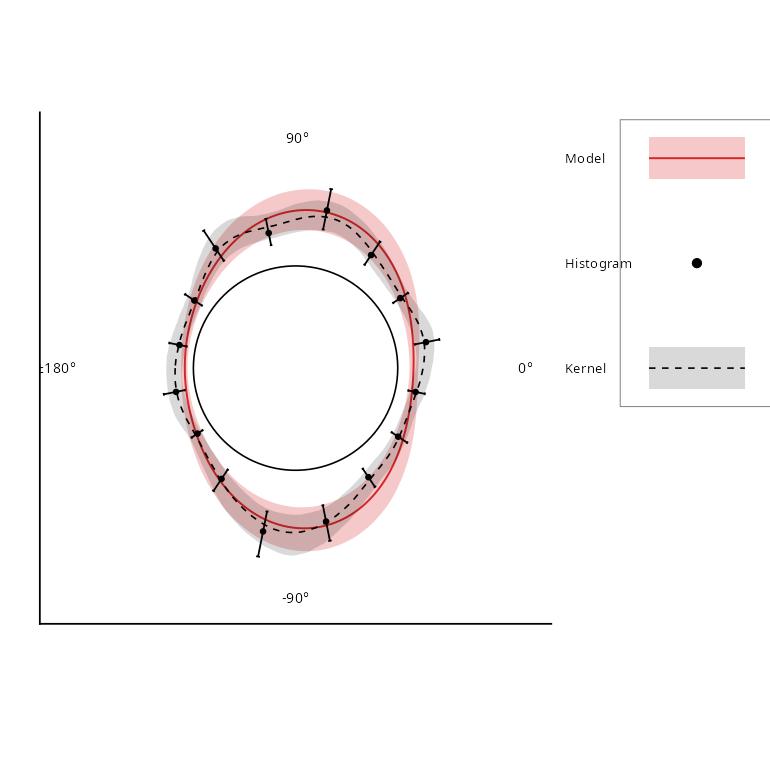

In [23]:
# Angle ticks use the twin's degree labels (locust_direction_plots.py):
# the mathematical orientation (0 at 3 o'clock, counter-clockwise) is the
# twin default for this x range, and the density-zero ring at radius 0.5
# is drawn as a black circle, as in the twin.
edge_radius <- 0.5
p_validation_polar <- ggplot(model_density, aes(theta, edge_radius + center)) +
  geom_ribbon(aes(ymin = edge_radius + low, ymax = edge_radius + high), fill = RED, alpha = 0.25) +
  geom_line(colour = RED, linewidth = 0.6) +
  geom_ribbon(data = kde_density, aes(ymin = edge_radius + low, ymax = edge_radius + high),
              fill = "black", alpha = 0.15) +
  geom_line(data = kde_density, linetype = "dashed", linewidth = 0.5) +
  geom_errorbar(data = hist_density, aes(ymin = edge_radius + low, ymax = edge_radius + high), width = 0.02) +
  geom_point(data = hist_density, size = 1.3) +
  geom_hline(yintercept = edge_radius, colour = "black", linewidth = 0.5) +
  scale_x_continuous(limits = c(-pi, pi),
                     breaks = c(-pi / 2, 0, pi / 2, pi),
                     labels = c("-90°", "0°", " 90°", "±180°     "),
                     expand = c(0, 0)) +
  scale_y_continuous(limits = c(0, edge_radius + max(model_density$high, kde_density$high) * 1.2)) +
  coord_polar(start = pi / 2, direction = -1) +
  # The twin shows no axis labels; keep blank radius tick labels like it.
  labs(x = "", y = "") +
  theme(axis.text.y = element_blank(), axis.ticks.y = element_blank())
p_validation_polar <- p_validation_polar | val_legend(framed = TRUE)
p_validation_polar <- p_validation_polar + plot_layout(widths = c(4, 1))
save_figure(p_validation_polar, "population_directional_validation", 7, 7)

## Individual heading distributions

The individual panels show how the population pattern is expressed by different locusts. Some animals strongly favor one side; others spread their headings across both directional tendencies. Differences in component concentration describe how consistently an animal follows each direction, while differences in weight describe the balance between them.

Read each fitted curve alongside that animal's observed headings and smoothed bootstrap estimate. Look for agreement in peak position and width, and for observations in regions where the fitted density is low. Sparse recordings naturally leave more uncertainty about the distribution's shape. These panels prevent a clear two-peaked population pattern from being mistaken for two equally prominent peaks in every animal.


The component arrows indicate their estimated directions. Their lengths combine component weight and concentration, so a prominent arrow reflects a directional tendency that is both prevalent and concentrated. The full density curve is the most informative summary when components overlap or directions span the angular boundary.

Outward ticks mark observed headings. Inward ticks highlight observations assigned low fitted density and help locate discrepancies between the model and data. They are descriptive annotations rather than a calibrated classification of unusual behavior.


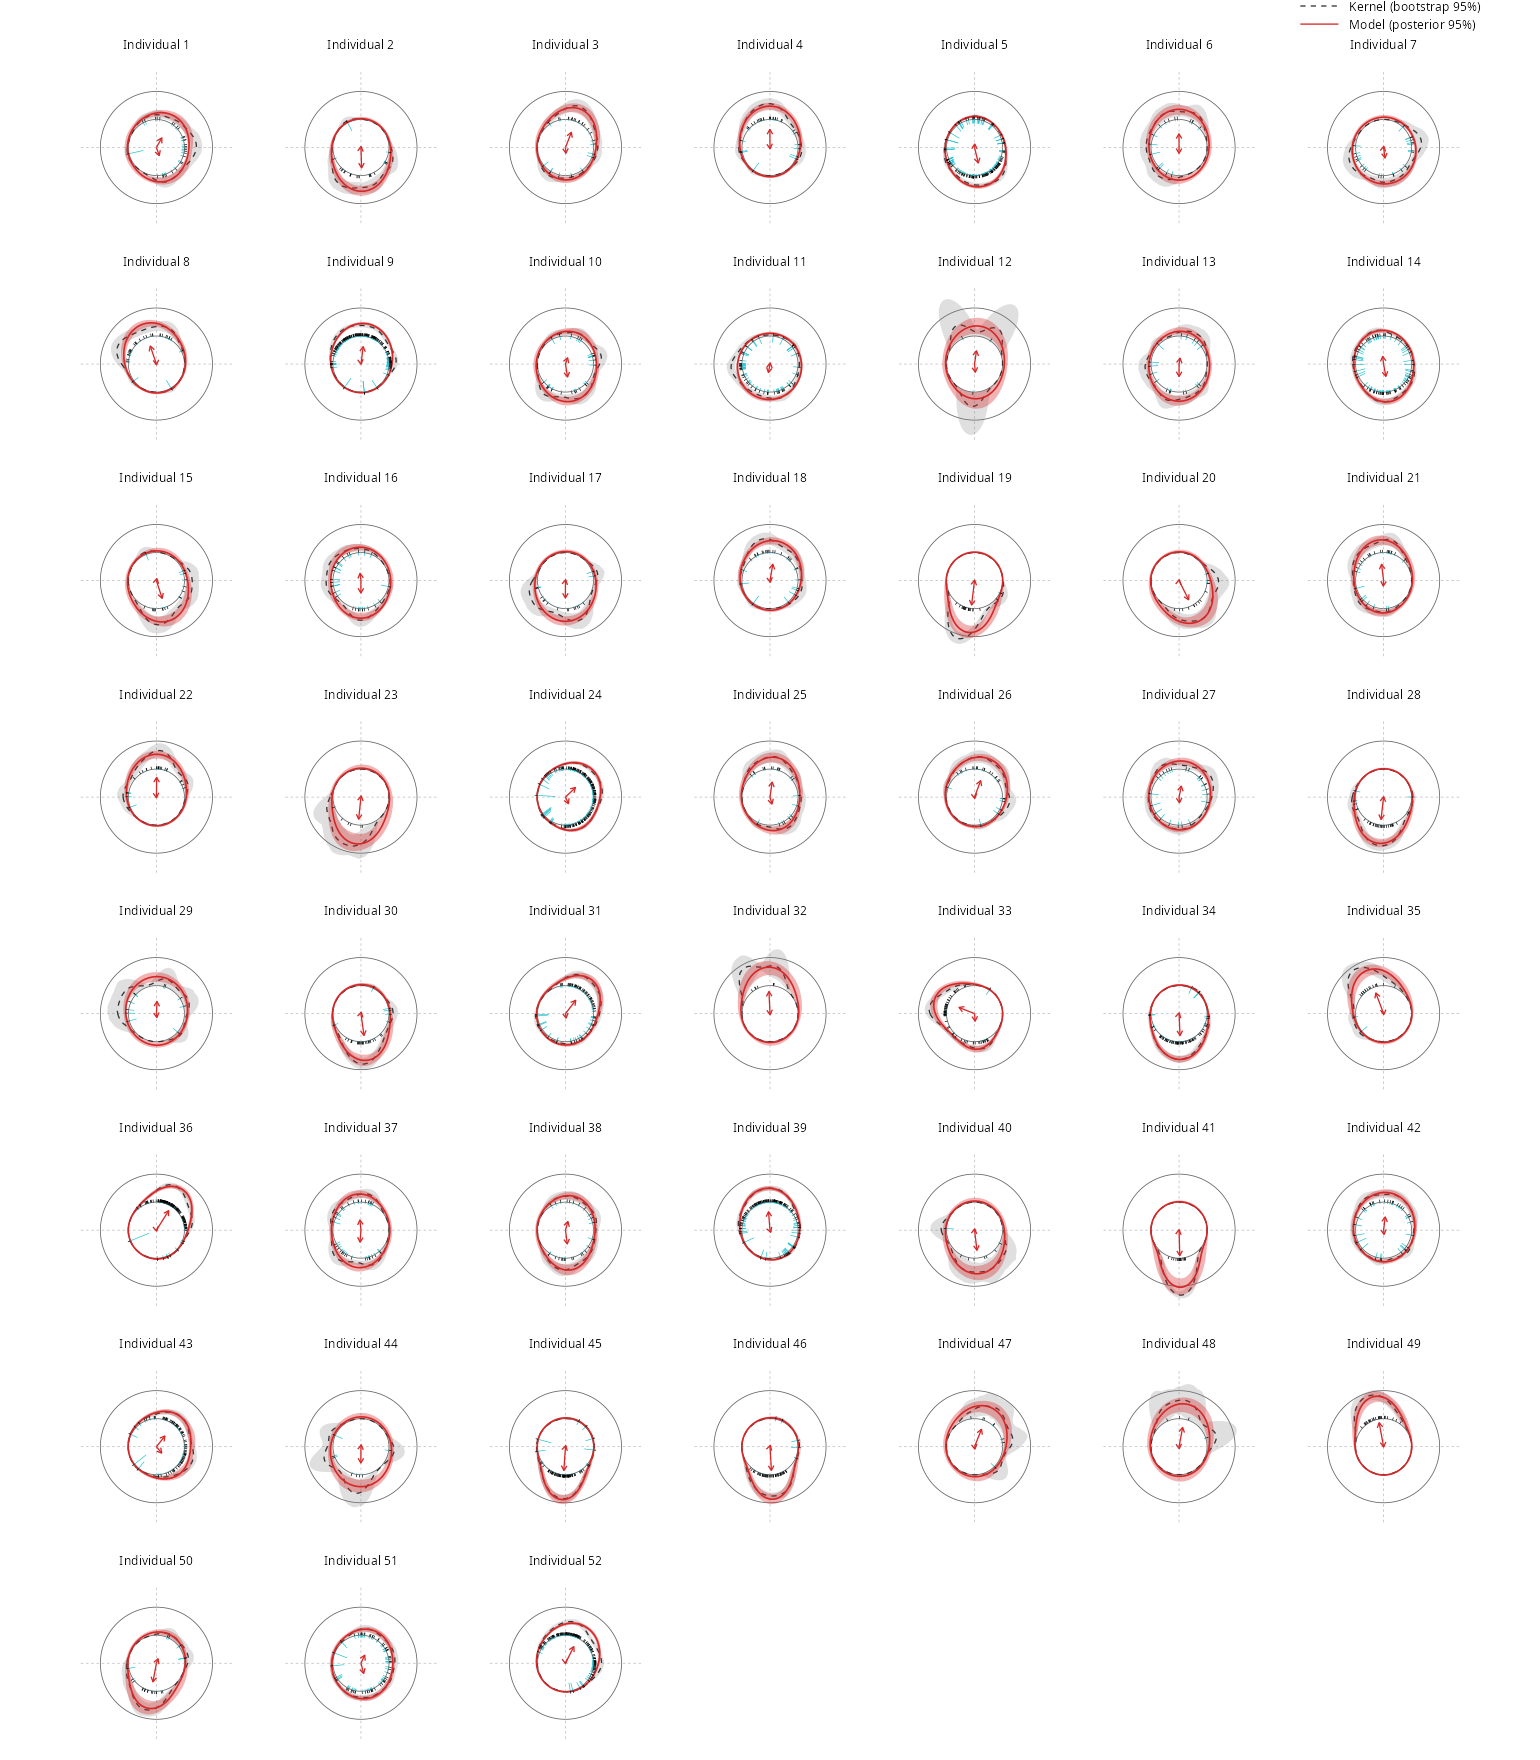

In [24]:
individual_theta <- -pi + (0:359) * (2 * pi / 360)
individual_curves <- vector("list", num_individuals)
individual_ticks <- vector("list", num_individuals)
individual_arrows <- vector("list", num_individuals)
for (i in seq_len(num_individuals)) {
  y <- wrap(df$direction[rows_by_animal[[i]]])
  mu <- rbind(state_bimodal$muone[i, ], state_bimodal$mutwo[i, ])
  kappa <- rbind(state_bimodal$kone[i, ], state_bimodal$ktwo[i, ])
  weight <- state_bimodal$weight[i, ]
  pdf <- mixture_grid(individual_theta, mu, kappa, clip_mixture_weight(weight))
  bounds <- t(apply(pdf, 1, quantile, probs = c(0.025, 0.975)))
  # Source semantics: PDF of posterior mean parameters, not mean PDF.
  mu_mean <- wrap(rowMeans(mu))
  kappa_mean <- rowMeans(kappa)
  w_mean <- clip_mixture_weight(mean(weight))
  plugin <- as.numeric(mixture_grid(individual_theta,
    matrix(mu_mean, ncol = 1L), matrix(kappa_mean, ncol = 1L), w_mean))
  kernel <- kde_basis(individual_theta, y, bw = 15)
  boot <- matrix(0, nrow = length(individual_theta), ncol = N_BOOT_KDE)
  set.seed(123L + 10000L + i - 1L)
  for (b in seq_len(N_BOOT_KDE)) {
    boot[, b] <- rowMeans(kernel[, sample.int(length(y), length(y), replace = TRUE), drop = FALSE])
  }
  kde <- t(apply(boot, 1, quantile, probs = c(0.025, 0.5, 0.975)))
  curve <- data.frame(individual = i, theta = individual_theta,
    model = plugin, model_low = bounds[, 1], model_high = bounds[, 2],
    kde_low = kde[, 1], kde = kde[, 2], kde_high = kde[, 3])
  # Close the periodic curve explicitly with the first grid value.
  end <- curve[1, ]
  end$theta <- pi
  individual_curves[[i]] <- rbind(curve, end)
  inv_grid <- 1 / plugin
  integral <- sum(diff(individual_theta) *
                  (head(inv_grid, -1L) + tail(inv_grid, -1L)) / 2)
  at_data <- as.numeric(mixture_grid(y, matrix(mu_mean, ncol = 1L),
                                     matrix(kappa_mean, ncol = 1L), w_mean))
  individual_ticks[[i]] <- data.frame(individual = i, theta = y,
    residual = -1 / (at_data * (integral + 1e-12)))
  individual_arrows[[i]] <- data.frame(individual = i, theta = mu_mean,
    length = c(w_mean, 1 - w_mean) * A1_safe(kappa_mean))
}
ppc_curves <- do.call(rbind, individual_curves)
ppc_ticks <- do.call(rbind, individual_ticks)
ppc_arrows <- do.call(rbind, individual_arrows)
ppc_levels <- seq_len(num_individuals)
for (name in c("ppc_curves", "ppc_ticks", "ppc_arrows")) {
  object <- get(name)
  object$individual <- factor(object$individual, levels = ppc_levels,
                              labels = paste("Individual", ppc_levels))
  assign(name, object)
}
rmax <- max(2, 1 + max(ppc_curves$model_high, ppc_curves$kde_high) * 1.15)
p_individual_ppc <- ggplot(ppc_curves, aes(theta, 1 + model, group = individual)) +
  geom_hline(yintercept = c(1, 2), colour = "grey40", linewidth = 0.25) +
  geom_vline(xintercept = c(-pi, -pi / 2, 0, pi / 2), colour = "grey70", linetype = "dashed", linewidth = 0.2) +
  geom_ribbon(aes(ymin = 1 + kde_low, ymax = 1 + kde_high), fill = "grey50", alpha = 0.25) +
  geom_line(aes(y = 1 + kde), colour = "grey20", linetype = "dashed", linewidth = 0.4) +
  geom_ribbon(aes(ymin = 1 + model_low, ymax = 1 + model_high), fill = RED, alpha = 0.35) +
  geom_line(colour = RED, linewidth = 0.5) +
  geom_segment(data = ppc_ticks,
    aes(x = theta, xend = theta, y = 1, yend = 1.1), inherit.aes = FALSE, linewidth = 0.2) +
  geom_segment(data = ppc_ticks,
    aes(x = theta, xend = theta, y = 1, yend = pmax(0, 1 + residual)),
    inherit.aes = FALSE, colour = "#17BECF", linewidth = 0.2) +
  geom_segment(data = ppc_arrows,
    aes(x = theta, xend = theta, y = 0, yend = length), inherit.aes = FALSE,
    colour = RED, linewidth = 0.4, arrow = grid::arrow(length = grid::unit(0.05, "inches"))) +
  scale_x_continuous(limits = c(-pi, pi), expand = c(0, 0)) +
  scale_y_continuous(limits = c(0, rmax), expand = c(0, 0)) +
  coord_polar(start = pi / 2, direction = -1) +
  facet_wrap(~ individual, ncol = 7) + theme_void(base_size = 8) +
  theme(strip.text = element_text(size = 8), panel.spacing = grid::unit(0.5, "lines"))

# Figure legend matching the Python twin: one-vertex line per key, so the
# legend entries come from the manual scales and nothing is drawn on the
# panels (manual guide overrides would warn on dev ggplot2; this does not).
ppc_key <- data.frame(theta = rep(0, 4), r = rep(0, 4),
  key = factor(rep(c("Kernel (bootstrap 95%)", "Model (posterior 95%)"), each = 2L),
               levels = c("Kernel (bootstrap 95%)", "Model (posterior 95%)")))

p_individual_ppc <- p_individual_ppc +
  geom_line(data = ppc_key,
    aes(x = theta, y = r, colour = key, linetype = key, group = key),
    inherit.aes = FALSE, linewidth = 0.4) +
  scale_colour_manual(name = NULL,
    values = c("Kernel (bootstrap 95%)" = "grey20", "Model (posterior 95%)" = RED)) +
  scale_linetype_manual(name = NULL,
    values = c("Kernel (bootstrap 95%)" = "dashed", "Model (posterior 95%)" = "solid")) +
  guides(colour = guide_legend(nrow = 2), linetype = guide_legend(nrow = 2)) +
  theme(legend.position = "top", legend.justification = "right",
        legend.key.width = grid::unit(1.1, "cm"),
        legend.key.height = grid::unit(0.25, "cm"),
        legend.text = element_text(size = 8),
        legend.spacing = grid::unit(0.4, "lines"))
save_figure(p_individual_ppc, "locust_directional_individual_ppc", 14, 16)

## Posterior predictive checks with simulated headings

To ask whether the fitted models could generate similar observations, we simulate another set of headings for each of the 52 animals. Each replicate uses a joint posterior draw and retains the observed number of headings per animal. Under the mixture, a heading is drawn from one of the two components according to that animal's weight. Under the one-component model, it is drawn from the animal's single von Mises distribution.

We then calculate the same histograms and smoothed densities for the replicated and observed headings, averaging animals equally for the population figures. The predictive bands include uncertainty in fitted parameters and the variation involved in generating a finite sample of headings. This makes them different from the earlier uncertainty band around the analytic population density.

The two-component model reproduces the lateral peaks and the intervening trough more closely. The one-component model gives a broader distribution with lower peaks and more density between them. Its population distribution can still have two broad concentrations because different animals prefer different directions. The individual panels show where a single distribution per animal is sufficient and where the mixture gives a better account of the observed shape.

These simulations assess the distribution of headings. The model does not reproduce their temporal order, so a close fit does not establish that it captures when an animal switches direction during a trajectory.


In [25]:
# The 52 animal sections of the predictive check are independent, so
# they run on a PSOCK cluster (fresh child R processes) instead of
# in the kernel. Workers are seeded per (model, animal), so results do
# not depend on the core count. (The earlier parallelize attempt used
# parallel::mclapply, whose fork is not safe under IRkernel: workers
# inherit the kernel's live ZMQ socket and the fork corrupts it. This
# also re-seeds the PPC draw streams relative to the original
# shared-stream implementation; the values move by Monte Carlo noise
# only, and the in-notebook gates are on the fit, not on these draws.
# The workers are plain top-level functions, which serialize as
# ~50-byte closures over the globalenv; all data flows through the
# explicit parLapply arguments.)
ppc_worker <- function(i, state, draws, n, theta_grid, bins, bin_widths,
                       bin_centers, rng_seed) {
  wrap <- function(x) (x + pi) %% (2 * pi) - pi
  circular_kde <- function(theta, y, bw) {
    yc <- circular::circular(wrap(y), units = "radians", template = "none",
                             modulo = "asis")
    z <- circular::circular(theta, units = "radians", template = "none",
                            modulo = "asis")
    circular::density.circular(yc, z = z, bw = bw,
                               kernel = "vonmises")$y
  }
  bin_heading_density <- function(y) {
    b <- findInterval(wrap(y), bins, rightmost.closed = TRUE)
    tabulate(b, nbins = length(bin_centers)) /
      (length(y) * bin_widths)
  }
  draw_vm <- function(n, mu, kappa) {
    if (!n) return(numeric())
    vmu <- circular::circular(mu, units = "radians", template = "none",
                              modulo = "2pi")
    as.numeric(circular::rvonmises(n, vmu, kappa,
      control.circular = list(units = "radians", template = "none",
                              modulo = "2pi")))
  }
  if (is.null(state$weight)) {
    rep_head <- function(draw) {
      wrap(draw_vm(n, state$muone[i, draw], state$kone[i, draw]))
    }
  } else {
    rep_head <- function(draw) {
      first <- rbinom(1, n, state$weight[i, draw])
      wrap(c(draw_vm(first, state$muone[i, draw], state$kone[i, draw]),
             draw_vm(n - first, state$mutwo[i, draw], state$ktwo[i,
               draw])))
    }
  }
  set.seed(rng_seed)
  y_rep <- lapply(draws, rep_head)
  list(hist = vapply(y_rep, bin_heading_density,
                     numeric(length(bin_centers))),
    population = vapply(y_rep, function(y) {
      circular_kde(theta_grid, y, bw = 30)
    }, numeric(length(theta_grid))),
    individual = vapply(y_rep, function(y) {
      circular_kde(theta_grid, y, bw = 15)
    }, numeric(length(theta_grid))))
}
ppc_task <- function(i, state, draws, n_all, theta_grid, bins,
                     bin_widths, bin_centers, rng_tag) {
  ppc_worker(i, state, draws, n_all[i], theta_grid, bins, bin_widths,
             bin_centers, rng_tag + i)
}
predictive_checks <- function(state, model, model_tag) {
  draws <- sample.int(nrow(state$draws), N_PREDICTIVE)
  n_all <- vapply(rows_by_animal, length, integer(1L))
  ppc_cores <- min(8L, max(2L, parallel::detectCores()))
  cl <- parallel::makePSOCKcluster(ppc_cores)
  on.exit(parallel::stopCluster(cl), add = TRUE)
  parallel::clusterEvalQ(cl, quote({
    .libPaths(c(Filter(nzchar, c(Sys.getenv("R_LIBS_USER"),
      Sys.getenv("R_LIBS_SITE"))), .libPaths()))
  }))
  parallel::clusterExport(cl, c("ppc_worker", "ppc_task"),
                          envir = globalenv())
  individuals <- parallel::parLapply(
    cl, seq_len(num_individuals), ppc_task,
    state = state, draws = draws, n_all = n_all, theta_grid = theta_grid,
    bins = bins, bin_widths = bin_width, bin_centers = bin_centers,
    rng_tag = SEED + 90000L + 1000L * model_tag)
  pop_hist <- matrix(0, nrow = length(bin_centers), ncol = length(draws))
  pop_kde <- matrix(0, nrow = length(theta_grid), ncol = length(draws))
  for (ind in individuals) {
    pop_hist <- pop_hist + ind$hist / num_individuals
    pop_kde <- pop_kde + ind$population / num_individuals
  }
  stopifnot(all(abs(colSums(pop_hist) * bin_width - 1) < 1e-10))
  population <- rbind(
    transform(density_frame(bin_centers, pop_hist), estimate = "Histogram"),
    transform(density_frame(theta_grid, pop_kde), estimate = "Von Mises KDE"))
  individual <- do.call(rbind, lapply(seq_along(individuals), function(i) {
    transform(density_frame(theta_grid, individuals[[i]]$individual),
              individual = paste("Individual", i))
  }))
  list(population = transform(population, model = model),
       individual = transform(individual, model = model))
}
set.seed(SEED + 1L)
ppc_bimodal <- predictive_checks(state_bimodal, "Bimodal", model_tag = 1L)
set.seed(SEED + 2L)
ppc_unimodal <- predictive_checks(state_unimodal, "Unimodal", model_tag = 2L)


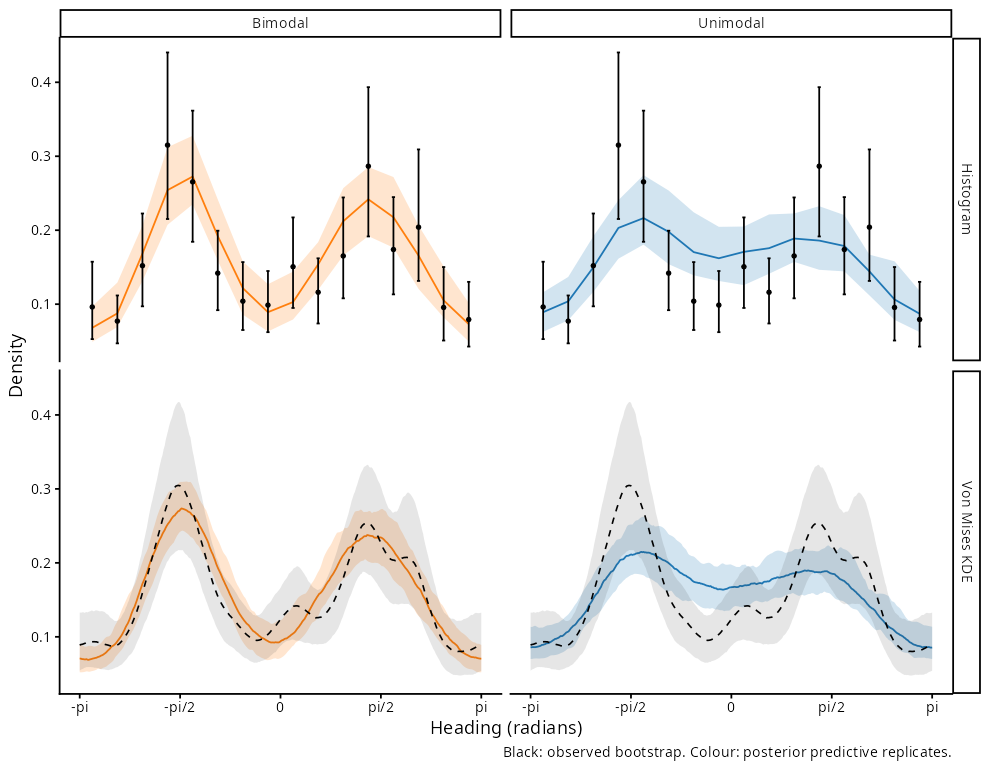

In [26]:
population_predictive <- rbind(ppc_bimodal$population, ppc_unimodal$population)
observed_hist <- transform(hist_density, estimate = "Histogram")
observed_kde <- transform(kde_density, estimate = "Von Mises KDE")
p_population_predictive <- ggplot(population_predictive, aes(theta, center)) +
  geom_ribbon(aes(ymin = low, ymax = high, fill = model), alpha = 0.2) +
  geom_line(aes(colour = model), linewidth = 0.55) +
  geom_errorbar(data = observed_hist, aes(ymin = low, ymax = high), width = 0.05) +
  geom_point(data = observed_hist, size = 1) +
  geom_ribbon(data = observed_kde, aes(ymin = low, ymax = high), alpha = 0.12) +
  geom_line(data = observed_kde, linetype = "dashed", linewidth = 0.5) +
  scale_colour_manual(values = c(Bimodal = ORANGE, Unimodal = BLUE)) +
  scale_fill_manual(values = c(Bimodal = ORANGE, Unimodal = BLUE)) +
  scale_x_continuous(breaks = angle_breaks, labels = angle_labels) +
  facet_grid(estimate ~ model) +
  labs(x = "Heading (radians)", y = "Density",
    caption = "Black: observed bootstrap. Colour: posterior predictive replicates.") +
  theme(legend.position = "none")
save_figure(p_population_predictive, "population_predictive_both_models", 9, 7)

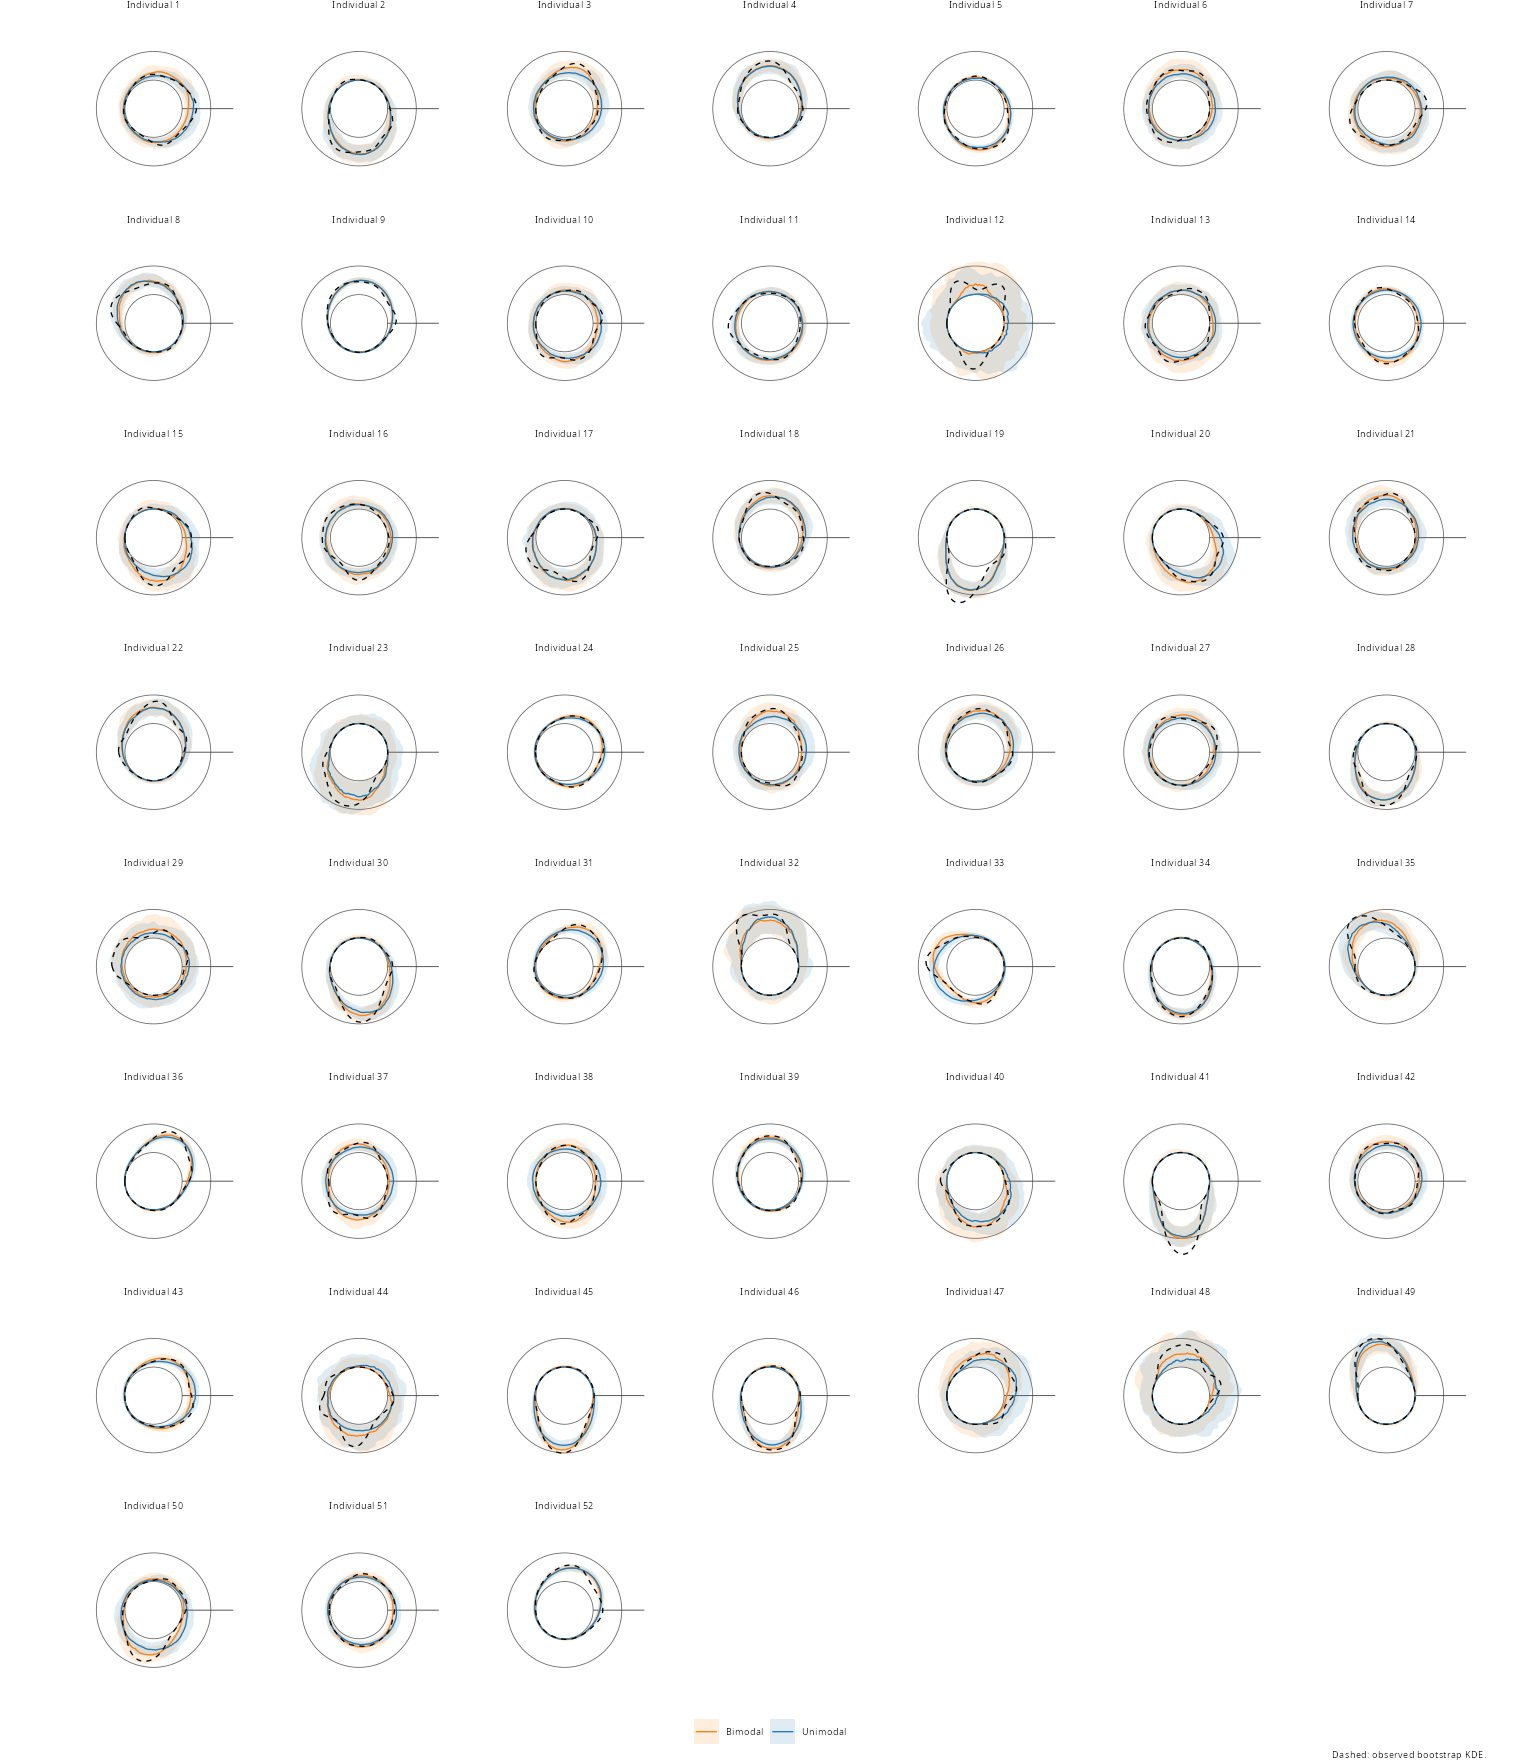

In [27]:
individual_predictive <- rbind(ppc_bimodal$individual, ppc_unimodal$individual)
individual_predictive$individual <- factor(individual_predictive$individual,
                                            levels = levels(ppc_curves$individual))
# Same radius convention as the other polar figures: density zero sits on
# the ring at radius 1 and the shared peak (largest model centre density
# over all individuals and both models) on the ring at radius 2, so the
# two models' peaks are directly comparable across the grid; the dashed
# observed bootstrap KDE is drawn on the same radius.
peak_max_ppc <- max(individual_predictive$center)
individual_predictive$r_low <- 1 + individual_predictive$low / peak_max_ppc
individual_predictive$r_center <- 1 + individual_predictive$center / peak_max_ppc
individual_predictive$r_high <- 1 + individual_predictive$high / peak_max_ppc
ppc_curves$kde_r <- 1 + ppc_curves$kde / peak_max_ppc
rmax_ppc <- max(2, 1 + 1.15 * max(individual_predictive$high,
  ppc_curves$kde) / peak_max_ppc)
p_individual_predictive <- ggplot(individual_predictive,
  aes(theta, r_center)) +
  geom_hline(yintercept = c(1, 2), colour = "grey40", linewidth = 0.25) +
  geom_segment(data = data.frame(x = 0, xend = 0, y = 1, yend = rmax_ppc),
    inherit.aes = FALSE,
    aes(x = x, xend = xend, y = y, yend = yend),
    colour = "grey20", linewidth = 0.25) +
  geom_ribbon(aes(ymin = r_low, ymax = r_high, fill = model), alpha = 0.14) +
  geom_line(aes(colour = model), linewidth = 0.4) +
  geom_line(data = ppc_curves, aes(y = kde_r),
    linetype = "dashed", linewidth = 0.4) +
  scale_colour_manual(values = c(Bimodal = ORANGE, Unimodal = BLUE)) +
  scale_fill_manual(values = c(Bimodal = ORANGE, Unimodal = BLUE)) +
  scale_x_continuous(limits = c(-pi, pi), expand = c(0, 0)) +
  scale_y_continuous(limits = c(0, rmax_ppc), expand = c(0, 0)) +
  coord_polar(start = pi / 2, direction = -1) +
  facet_wrap(~ individual, ncol = 7) + theme_void(base_size = 8) +
  labs(colour = NULL, fill = NULL, caption = "Dashed: observed bootstrap KDE.") +
  theme(legend.position = "bottom")
save_figure(p_individual_predictive, "individual_predictive_both_models", 14, 16)

## Testing the directional predictions of the two hypotheses

We now return to the experiment's biological question. The optic-flow hypothesis predicts continued forward movement with the virtual groups. The vectorial-encoding hypothesis predicts turns toward either of the two groups. We assess these predictions using the complete fitted mixture, whose directions, concentrations, and weights have been estimated from the headings.

For the population mixture $f_0$, with individual deviations set to zero, define

$$
p_{\to}=f_0(0),\qquad
p_{\updownarrow}=\frac{f_0(-\pi/2)+f_0(+\pi/2)}{2}.
$$

The first quantity is the predictive density at the forward direction. The second is the average predictive density at the two lateral directions. Averaging makes the comparison interpretable per predicted direction, so specifying two alternatives does not automatically double the lateral score. Both quantities equal $1/(2\pi)\approx0.159$ for a uniform heading distribution.

The fitted population density is approximately **0.28 per radian at the lateral directions**, averaged across the two sides, and **0.08 per radian at the forward direction**. The lateral average lies above the uniform reference, while the forward value lies below it. Together with the observed peaks and predictive checks, this favors the pattern of turns toward neighboring groups predicted by the **vectorial-encoding hypothesis** over the forward-marching prediction of the **optic-flow hypothesis**.

These values are densities, rather than probabilities of an exactly specified heading. Probabilities for angular ranges would be obtained by integrating the fitted density over those ranges. The comparison provides evidence about the hypotheses' behavioral predictions; it does not estimate the probability that a particular neural circuit implements them.

The individual figures repeat the calculation using each animal's parameters. Their probability panel reports the posterior fraction for which the lateral average exceeds the forward density,

$$
P\!\left(p_{\updownarrow,i}>p_{\to,i}\mid Y\right).
$$

This shows how strongly the density comparison favors lateral headings for each animal while incorporating uncertainty in its component directions, concentrations, and weights. The displayed 95% intervals for density are calculated on the log-density scale and transformed back.


### Log density and component alignment

The fixed-direction log-density plots evaluate the same forward and lateral predictions on a logarithmic scale. They average the per-draw log densities at the specified angles, rather than evaluating held-out observations as in PSIS-LOO. Their error bars are calculated as $1.96\,\mathrm{sd}(\log p)/\sqrt{S}$ using the raw number of posterior draws $S$, without an effective-sample-size adjustment. They are not 95% posterior credible intervals; use the preceding density intervals to assess uncertainty in the fitted predictions.

The “pooled” row averages individual log densities with equal animal weights. On the density scale, this is a geometric mean of individual densities. It differs from both the shared population mixture and an arithmetic average of individual densities.

The final alignment plots isolate the orientation of the fitted components:

$$
A_{\to}=\sum_{k=1}^{2}w_k\cos\mu_k,\qquad
A_{\perp}=\sum_{k=1}^{2}w_k\cos\!\left[2(\mu_k-\pi/2)\right],
$$

with $w_1=\omega$ and $w_2=1-\omega$. Doubling the angle in the lateral score makes leftward and rightward components reinforce one another. These scores use directions and weights, while the density comparison also includes concentration. A broad component can therefore have a high alignment score even when its headings are only weakly concentrated. The accompanying probability panel compares the two alignment scores across posterior draws; it answers a different question from the earlier probability that lateral density exceeds forward density.


  individual    hypothesis    center        low      high probability
1          1    Optic flow 0.0771327 0.05817435 0.1009854           1
2          1 Vec. encoding 0.2771139 0.25280319 0.3021021           1


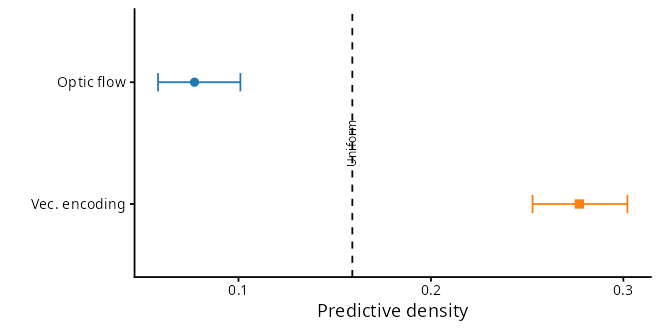

In [28]:
hypothesis_arrays <- function(state, clip = FALSE) {
  forward <- mixture_at(0, state, clip)
  left <- mixture_at(-pi / 2, state, clip)
  right <- mixture_at(pi / 2, state, clip)
  list(forward = forward, perpendicular = log_add(left, right) - log(2))
}
hyp_pop <- hypothesis_arrays(population_state)
hyp_ind <- hypothesis_arrays(state_bimodal, clip = TRUE)
interval_row <- function(x, mode = c("density", "elpd", "alignment")) {
  mode <- match.arg(mode)
  if (mode == "elpd") {
    center <- mean(x)
    error <- 1.96 * sd(x) / sqrt(length(x))
    return(c(center = center, low = center - error, high = center + error))
  }
  bounds <- hdi(x)
  if (mode == "density") {
    return(c(center = exp(median(x)), low = exp(unname(bounds[1])), high = exp(unname(bounds[2]))))
  }
  c(center = mean(x), low = unname(bounds[1]), high = unname(bounds[2]))
}
make_hyp_table <- function(arrays, mode, pooled = FALSE) {
  f <- arrays$forward
  p <- arrays$perpendicular
  stopifnot(is.matrix(f), identical(dim(f), dim(p)))
  labels <- as.character(seq_len(nrow(f)))
  if (pooled) {
    f <- rbind(f, colMeans(f))
    p <- rbind(p, colMeans(p))
    labels <- c(labels, "Pooled")
  }
  do.call(rbind, lapply(seq_len(nrow(f)), function(i) {
    z <- rbind(interval_row(f[i, ], mode), interval_row(p[i, ], mode))
    data.frame(individual = labels[i], hypothesis = c("Optic flow", "Vec. encoding"),
      center = z[, 1], low = z[, 2], high = z[, 3],
      probability = mean(p[i, ] > f[i, ]), row.names = NULL)
  }))
}
population_dots <- function(table, label, baseline, invert = FALSE,
                          baseline_label = NULL) {
  levels <- if (invert) c("Optic flow", "Vec. encoding")
          else c("Vec. encoding", "Optic flow")
  p <- ggplot(table, aes(center, factor(hypothesis, levels = levels),
          colour = hypothesis, shape = hypothesis)) +
    geom_errorbar(aes(xmin = low, xmax = high), orientation = "y", width = 0.15) +
    geom_point(size = 2.5) + geom_vline(xintercept = baseline, linetype = "dashed") +
    scale_colour_manual(values = HYP_COLORS) +
    scale_shape_manual(values = c("Optic flow" = 16, "Vec. encoding" = 15)) +
    labs(x = label, y = "") + theme(legend.position = "none")
  if (!is.null(baseline_label)) {
    # Python rotates a label next to the dashed baseline; vjust = 1 puts
    # the text body to the left of the anchor once angle = 90.
    p <- p +
      annotate("text",
               x = baseline - diff(range(table$center)) * 0.015, y = 1.5,
               label = baseline_label, angle = 90, hjust = 0.5, vjust = 1,
               size = 2.8)
  }
  p
}
individual_dots <- function(table, label, baseline, limits = NULL) {
  labels <- unique(table$individual)
  table$individual <- factor(table$individual, levels = rev(labels))
  dodge <- position_dodge(width = 0.5)
  main <- ggplot(table, aes(center, individual, colour = hypothesis, shape = hypothesis)) +
    geom_errorbar(aes(xmin = low, xmax = high), orientation = "y", width = 0.2, position = dodge) +
    geom_point(size = 1.6, position = dodge) +
    geom_vline(xintercept = baseline, linetype = "dashed") +
    scale_colour_manual(values = HYP_COLORS) +
    scale_shape_manual(values = c("Optic flow" = 16, "Vec. encoding" = 15)) +
    labs(x = label, y = "Individual", tag = "a.") +
    theme(legend.position = "top",
          legend.background = element_rect(fill = "white", colour = "grey50"))
  if (!is.null(limits)) main <- main + coord_cartesian(xlim = limits)
  probs <- table[!duplicated(table$individual), ]
  probability <- ggplot(probs, aes(probability, individual)) +
    geom_point(size = 1.6) + geom_vline(xintercept = 0.5, linetype = "dashed") +
    geom_vline(xintercept = 1) + scale_x_continuous(limits = c(0, 1.02)) +
    labs(x = "P(Vec. encoding > Optic flow)", y = "", tag = "b.") +
    theme(axis.text.y = element_blank(), axis.ticks.y = element_blank())
  main + probability + plot_layout(widths = c(1.35, 1))
}
pop_density_table <- make_hyp_table(hyp_pop, "density")
print(pop_density_table)
save_figure(population_dots(pop_density_table, "Predictive density", 1 / (2 * pi),
  baseline_label = "Uniform"),
  "locust_directional_hypothesis_horizontal", 6, 3)

  individual    hypothesis    center       low      high probability
1          1    Optic flow -2.566744 -2.568964 -2.564524           1
2          1 Vec. encoding -1.284614 -1.285327 -1.283900           1


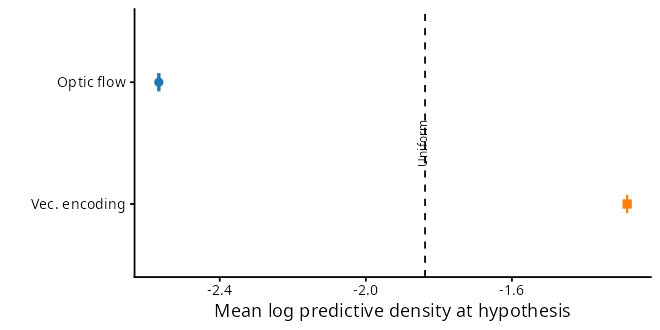

In [29]:
pop_elpd_table <- make_hyp_table(hyp_pop, "elpd")
print(pop_elpd_table)
save_figure(population_dots(pop_elpd_table, "Mean log predictive density at hypothesis",
  -log(2 * pi), baseline_label = "Uniform"),
  "locust_directional_hypothesis_horizontal_elpd", 6, 3)


    individual    hypothesis      center          low       high probability
1            1    Optic flow 0.182421862 0.1184637175 0.29280716   0.5781250
2            1 Vec. encoding 0.194751839 0.1518461839 0.25491415   0.5781250
3            2    Optic flow 0.058609371 0.0182910595 0.14425793   0.9996250
4            2 Vec. encoding 0.283345336 0.2098531662 0.37471593   0.9996250
5            3    Optic flow 0.104248268 0.0468391326 0.20424334   0.9735000
6            3 Vec. encoding 0.253903622 0.1905669114 0.33513780   0.9735000
7            4    Optic flow 0.080589076 0.0373449933 0.15299171   0.9991875
8            4 Vec. encoding 0.244733881 0.1931807300 0.30913238   0.9991875
9            5    Optic flow 0.112325519 0.0762602611 0.15801842   0.9996875
10           5 Vec. encoding 0.244578025 0.2084804792 0.28267451   0.9996875
11           6    Optic flow 0.090146401 0.0245473545 0.18241227   0.9782500
12           6 Vec. encoding 0.231213231 0.1591610448 0.31795480   0.9782500

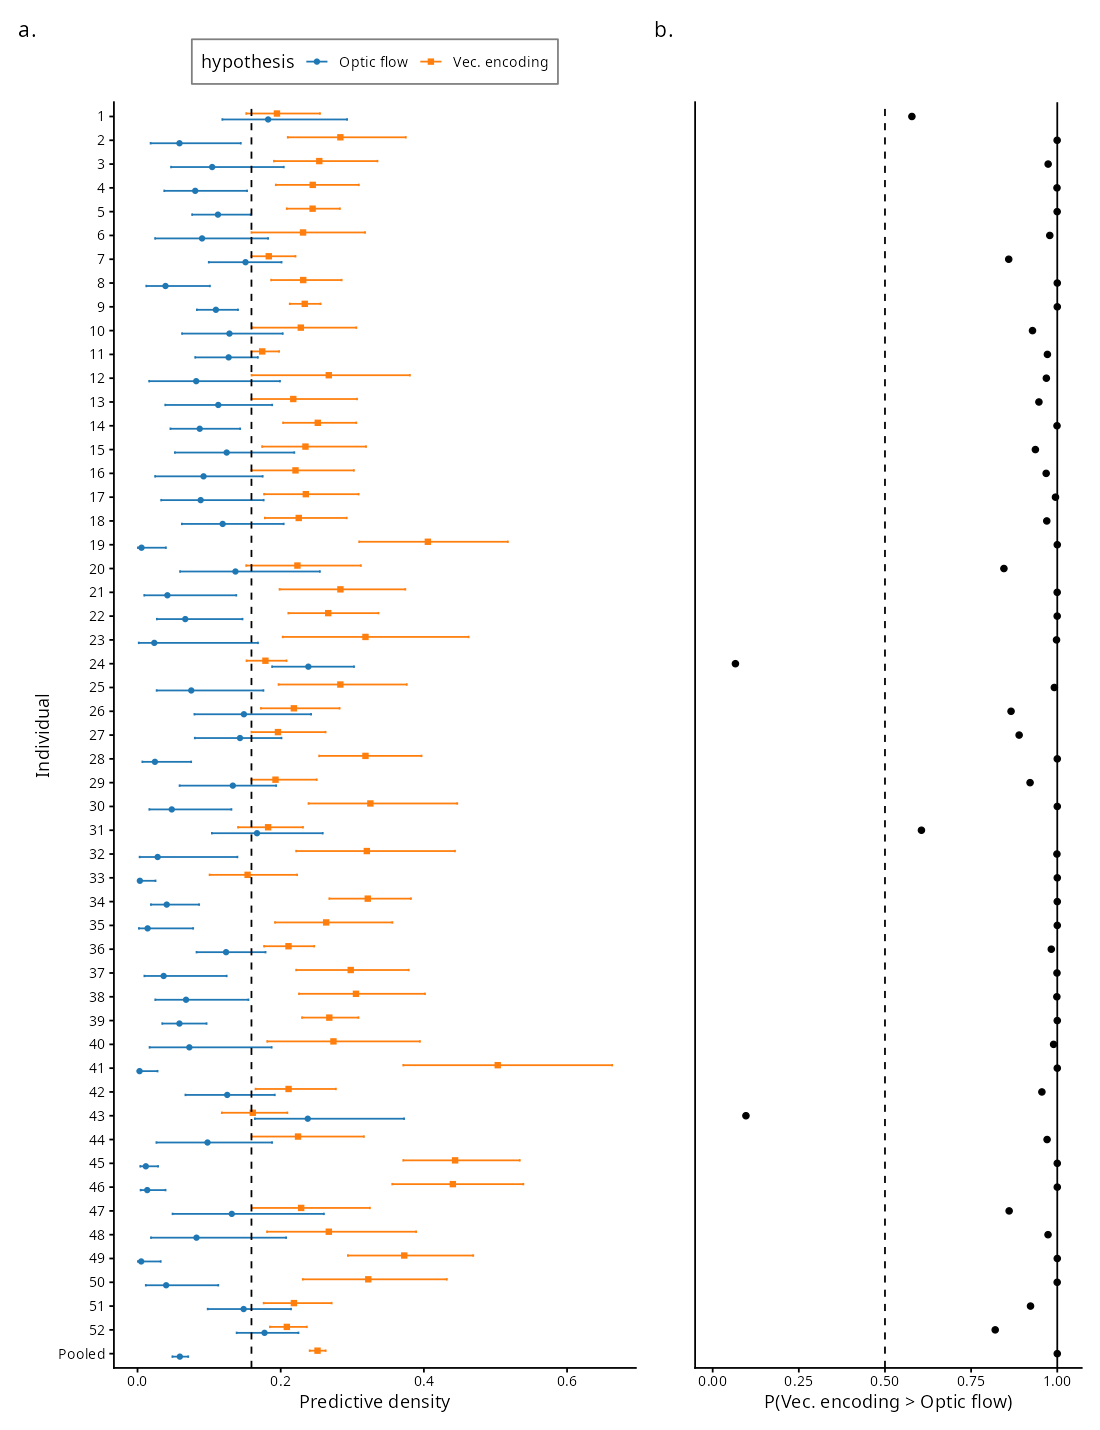

In [30]:
individual_density_table <- make_hyp_table(hyp_ind, "density", pooled = TRUE)
print(individual_density_table)
save_figure(individual_dots(individual_density_table, "Predictive density", 1 / (2 * pi)),
  "locust_directional_hypothesis_individual_ab", 10, 13)


    individual    hypothesis     center        low       high probability
1            1    Optic flow -1.6973527 -1.7008599 -1.6938455   0.5781250
2            1 Vec. encoding -1.6369155 -1.6390039 -1.6348271   0.5781250
3            2    Optic flow -2.9024702 -2.9110020 -2.8939385   0.9996250
4            2 Vec. encoding -1.2657552 -1.2680788 -1.2634316   0.9996250
5            3    Optic flow -2.2974108 -2.3033780 -2.2914435   0.9735000
6            3 Vec. encoding -1.3793617 -1.3816288 -1.3770947   0.9735000
7            4    Optic flow -2.5500596 -2.5557763 -2.5443429   0.9991875
8            4 Vec. encoding -1.4046379 -1.4065017 -1.4027742   0.9991875
9            5    Optic flow -2.1948202 -2.1977329 -2.1919074   0.9996875
10           5 Vec. encoding -1.4111031 -1.4123135 -1.4098927   0.9996875
11           6    Optic flow -2.5287922 -2.5377789 -2.5198056   0.9782500
12           6 Vec. encoding -1.4637799 -1.4667510 -1.4608088   0.9782500
13           7    Optic flow -1.922713

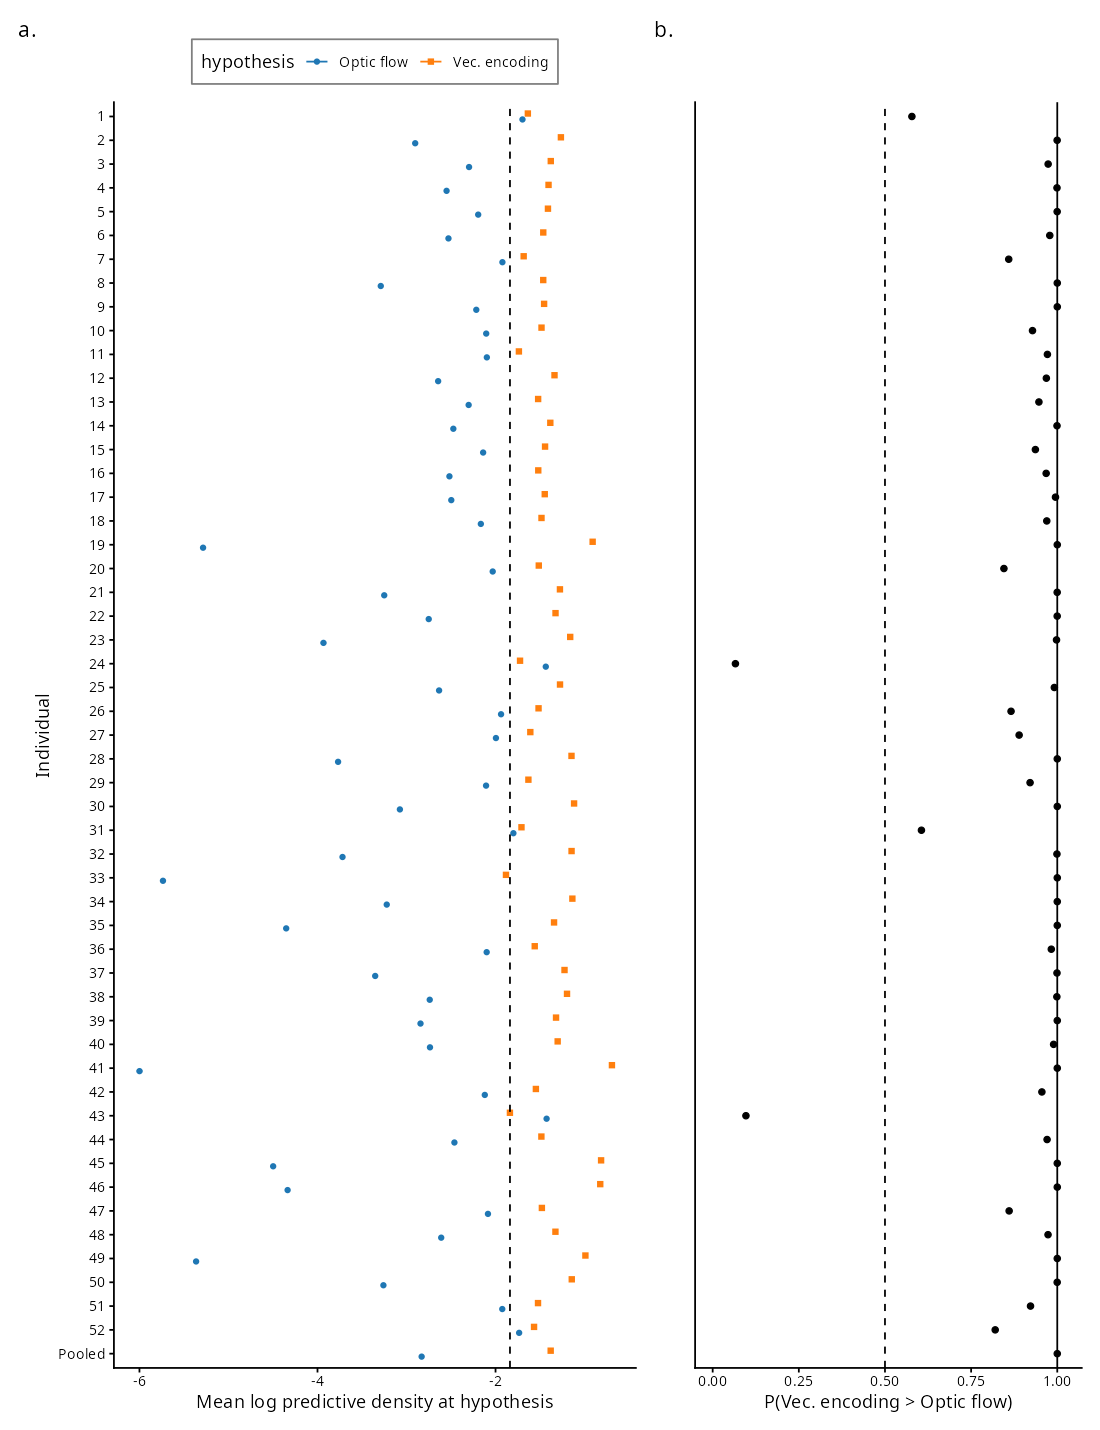

In [31]:
individual_elpd_table <- make_hyp_table(hyp_ind, "elpd", pooled = TRUE)
print(individual_elpd_table)
save_figure(individual_dots(individual_elpd_table, "Mean log predictive density at hypothesis", -log(2 * pi)),
  "locust_directional_hypothesis_individual_elpd_ab", 10, 13)


  individual    hypothesis    center        low      high probability
1          1    Optic flow 0.1331832 0.06153364 0.2054376           1
2          1 Vec. encoding 0.9574284 0.91497287 0.9936267           1


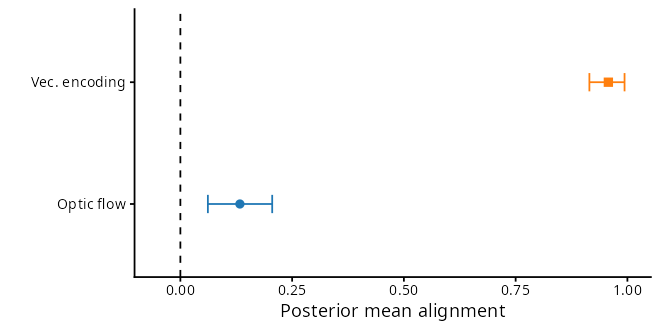

In [32]:
alignment_arrays <- function(state) {
  w <- state$weight
  stopifnot(is.matrix(w), identical(dim(w), dim(state$muone)))
  list(forward = w * cos(state$muone) + (1 - w) * cos(state$mutwo),
       perpendicular = w * cos(2 * (state$muone - pi / 2)) +
         (1 - w) * cos(2 * (state$mutwo - pi / 2)))
}
# Weight-only alignment is the source estimand; no A1(kappa) factor.
align_pop <- alignment_arrays(population_state)
align_ind <- alignment_arrays(state_bimodal)
pop_alignment_table <- make_hyp_table(align_pop, "alignment")
print(pop_alignment_table)
save_figure(population_dots(pop_alignment_table, "Posterior mean alignment", 0,
  invert = TRUE) +
              coord_cartesian(xlim = c(-0.05, 1)),
  "locust_directional_alignment_horizontal", 6, 3)


    individual    hypothesis        center          low         high
1            1    Optic flow  0.4595810039  0.160902831  0.741496502
2            1 Vec. encoding  0.4905246589 -0.021272383  0.996754825
3            2    Optic flow  0.0351754762 -0.195255002  0.287170480
4            2 Vec. encoding  0.9612183900  0.861881581  0.999999401
5            3    Optic flow  0.2856006613  0.070114746  0.497018999
6            3 Vec. encoding  0.7646929720  0.499396718  0.997383950
7            4    Optic flow  0.0005678127 -0.250472681  0.260429354
8            4 Vec. encoding  0.9583785068  0.853935003  0.999999957
9            5    Optic flow  0.2069407380  0.067716016  0.339282847
10           5 Vec. encoding  0.8854582875  0.760420433  0.995903710
11           6    Optic flow -0.0203135707 -0.348191462  0.311900918
12           6 Vec. encoding  0.9180532884  0.739478552  0.999999882
13           7    Optic flow  0.1402922958 -0.196988785  0.468655283
14           7 Vec. encoding  0.89

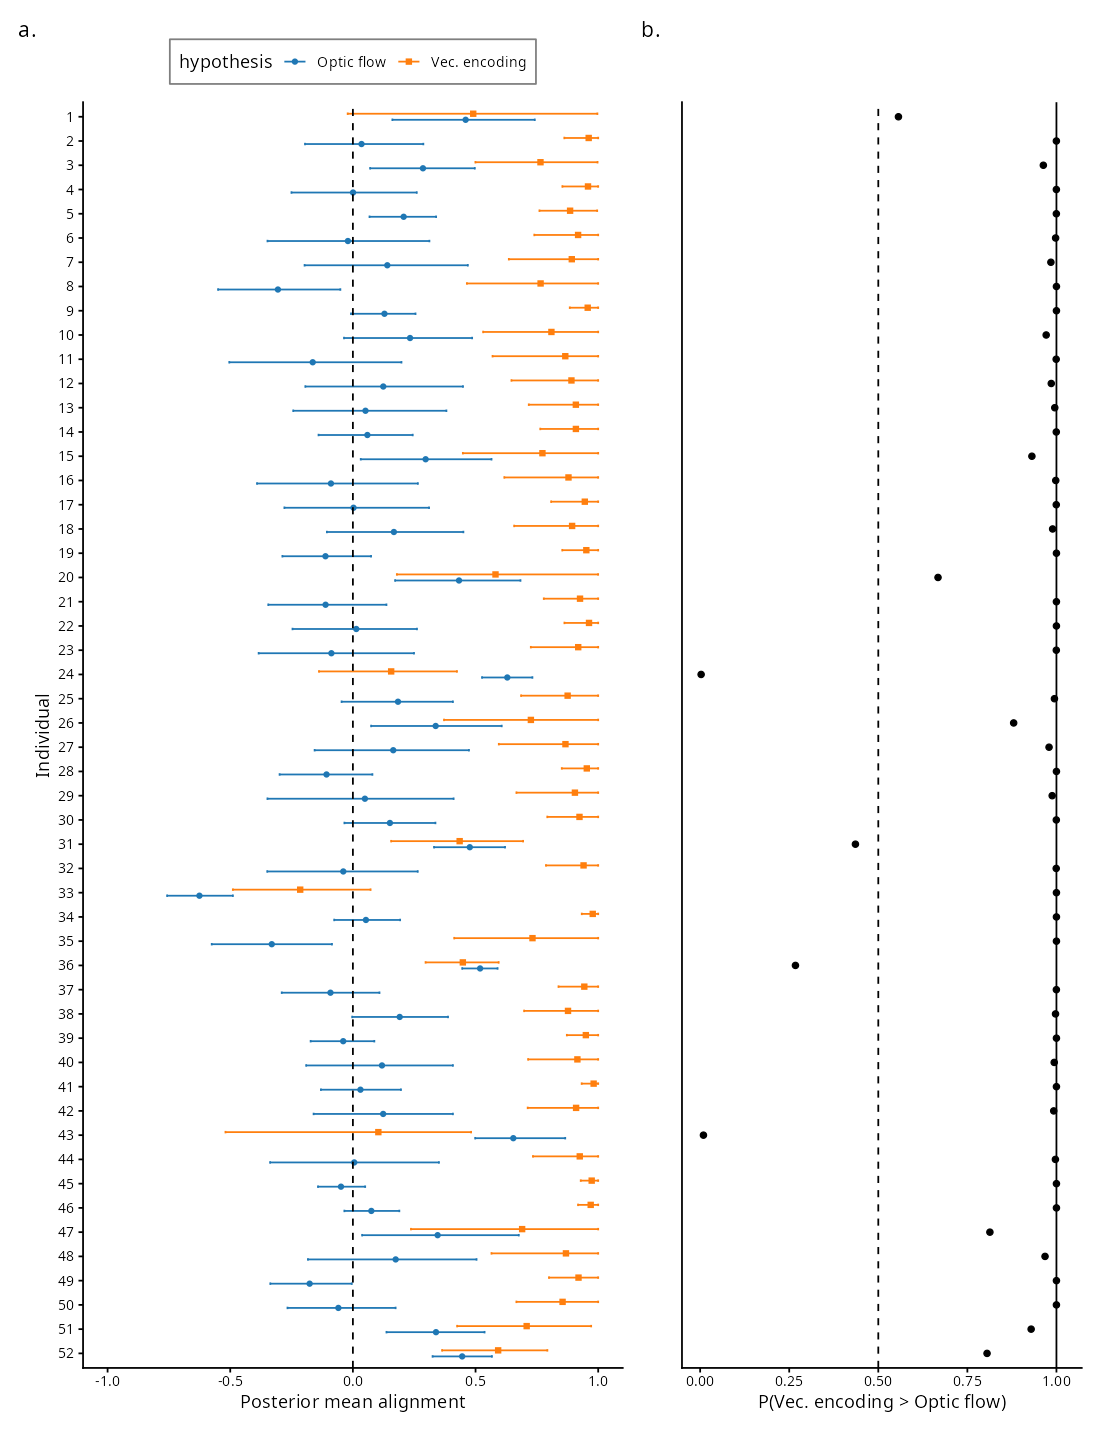

In [33]:
individual_alignment_table <- make_hyp_table(align_ind, "alignment")
print(individual_alignment_table)
save_figure(individual_dots(individual_alignment_table, "Posterior mean alignment", 0,
                            limits = c(-1, 1)),
  "locust_directional_alignment_individual_ab", 10, 13)


## Biological interpretation

In this virtual-reality arrangement, the locusts' headings concentrate toward the groups on their left and right. The two-component mixture captures those peaks and their separation more successfully than a single preferred direction per animal. Its fitted density is also higher at the lateral directions predicted by vectorial encoding than at the forward direction predicted by the optic-flow hypothesis.

The hierarchy shows how that shared pattern accommodates individual variation. Animals differ in their preferred directions, the concentration of their headings, and how strongly they favor one component. The population's two peaks therefore summarize a range of individual responses, rather than requiring every animal to divide its headings equally between the two sides.

The result supports the vectorial-encoding hypothesis's prediction of choosing between lateral groups in this experiment. The distribution of headings provides the link between the behavioral observations and that prediction. Establishing the underlying neural implementation would require evidence beyond these movement data.
